# Final Results and Research Question Summary

## Prediction Target

This project predicts the severity of an already recorded New Zealand road crash.

The target variable is `crashSeverity`, with four classes:

- Non-Injury Crash
- Minor Crash
- Serious Crash
- Fatal Crash

The project does not predict crash occurrence or the probability of a future crash.

## Project Contribution

The project investigates baseline model performance, class-imbalance handling, leakage auditing, spatial road-network features, external contextual information, feature ablation, five-seed evaluation and severe-class errors.

TreeSHAP analysis and leave-one-context-out ablation were regenerated for the corrected seed-42 final national model.

## Final National Context Model

The final model uses the same 30 CAS baseline predictors as the earlier experiment notebooks and adds four contextual predictors:

- distance to the nearest derived road-network junction;
- NZDep2023 socioeconomic deprivation score;
- LCDB land-cover group; and
- LINZ elevation.

The combined model contains 34 predictors. GCH2023 is not included.

The paired experiment used seeds 42, 7, 21, 84 and 123. Within each seed, CAS-only and contextual models were evaluated on the same stratified train/test split.

Mean Accuracy increased from 0.4940 to 0.5184, while mean Macro F1 increased from 0.3288 to 0.3389. Accuracy and Macro F1 improved in all five seeds. The mean paired Macro F1 gain was +0.0101.

Mean Balanced Accuracy decreased from 0.4062 to 0.3947, Fatal recall decreased from 0.3077 to 0.2215, and Serious recall decreased from 0.3944 to 0.3756.

Fatal recall decreased in all five seeds. Serious recall decreased in three seeds and increased in two.

The contextual model improved Accuracy and Macro F1 across these splits, with a trade-off in severe-class sensitivity.

## Severe-Class Error Analysis

The seed-42 test set contained 65 Fatal crashes and 501 Serious crashes.

Among Fatal crashes:

- 21.54% were classified exactly as Fatal;
- 46.15% were classified as Serious;
- 67.69% remained within the broader Fatal/Serious category;
- 32.31% were downgraded to Minor or Non-Injury; and
- 15.38% were classified as Non-Injury.

Among Serious crashes:

- 39.52% were classified exactly as Serious;
- 6.19% were classified as Fatal;
- 45.71% remained within the broader Fatal/Serious category;
- 34.33% were classified as Minor; and
- 54.29% were downgraded to Minor or Non-Injury.

Severe-class under-classification remains a substantial limitation.

## Earlier Experiments and Interpretation

The independent spatial, socioeconomic, rurality, land-cover, terrain and State Highway experiments retain their own reported results. Their scores should be distinguished from the final paired national comparison.

State Highway analysis used a separate 10,401-crash population and should be interpreted separately from national performance.

The regenerated SHAP rankings and four-context ablation describe the corrected seed-42 model. Earlier directional interpretations and GCH-selection findings remain separate historical analyses.

SHAP describes model behaviour and does not establish causal relationships.

In [1]:
import pandas as pd

rq_summary = pd.DataFrame([
    {
        "Research Question": (
            "RQ1: How accurately can machine-learning models classify "
            "the severity of recorded New Zealand road crashes?"
        ),
        "Main Evidence": (
            "In the earlier baseline comparison, Weighted XGBoost "
            "achieved the highest Macro F1 (0.3272), while Balanced "
            "Logistic Regression achieved the highest Balanced "
            "Accuracy (0.4129)."
        ),
        "Conclusion": (
            "The models identified severity patterns, but performance "
            "was limited by class imbalance and weak discrimination "
            "of rare severe classes. Weighted XGBoost was selected "
            "for subsequent experiments using Macro F1."
        )
    },
    {
        "Research Question": (
            "RQ2: Does engineered spatial road-network information "
            "improve recorded-crash severity classification?"
        ),
        "Main Evidence": (
            "In the independent junction-distance experiment, "
            "five-seed mean Macro F1 increased from 0.3288 to 0.3323 "
            "and improved in four of five seeds."
        ),
        "Conclusion": (
            "Junction distance provided a small, generally consistent "
            "improvement in Macro F1. Balanced Accuracy and severe-class "
            "recall did not improve. These results belong to the earlier "
            "independent spatial experiment."
        )
    },
    {
        "Research Question": (
            "RQ3: Do external State Highway road-context features "
            "provide additional predictive value?"
        ),
        "Main Evidence": (
            "On the separate 10,401-crash State Highway subset, "
            "CAS + Junction + ONRC increased five-seed mean Macro F1 "
            "from 0.3148 to 0.3259."
        ),
        "Conclusion": (
            "ONRC provided additional predictive information when "
            "combined with junction distance. State Highway scores "
            "are interpreted separately because the crash population "
            "differs from the national experiment."
        )
    },
    {
        "Research Question": (
            "RQ4: Do national socioeconomic, environmental and terrain "
            "features provide complementary predictive information?"
        ),
        "Main Evidence": (
            "The final model added junction distance, NZDep2023 score, "
            "LCDB land-cover group and elevation to the established "
            "30-predictor CAS baseline. Mean Macro F1 increased from "
            "0.3288 to 0.3389 and mean Accuracy from 0.4940 to 0.5184. "
            "Both improved in all five seeds."
        ),
        "Conclusion": (
            "The selected contextual features improved Accuracy and "
            "Macro F1 across the evaluated splits. This came with "
            "lower mean Balanced Accuracy and severe-class recall."
        )
    },
    {
        "Research Question": (
            "RQ5: Which factors contribute most strongly to the "
            "final national crash-severity predictions?"
        ),
        "Main Evidence": (
            "Regenerated seed-42 TreeSHAP analysis ranked junction "
            "distance 1st globally, LCDB land cover 3rd, NZDep2023 "
            "score 4th and elevation 9th. Their Fatal-class ranks "
            "were 2nd, 7th, 3rd and 4th respectively."
        ),
        "Conclusion": (
            "The fitted model used all four contextual predictors "
            "alongside the original CAS attributes. SHAP importance "
            "describes contributions to raw class margins, not causal "
            "effects or a simple directional relationship with severity."
        )
    },
    {
        "Research Question": (
            "RQ6: How consistent are the final results across random "
            "splits, and where does the selected model fail?"
        ),
        "Main Evidence": (
            "Macro F1 improved in all five seeds, with mean paired "
            "gain +0.0101. Fatal recall decreased in all five seeds, "
            "with mean paired change -0.0862. Serious recall decreased "
            "in three of five seeds. In seed-42 error analysis, 67.69% "
            "of Fatal crashes remained within the Fatal/Serious "
            "category, while 54.29% of Serious crashes were "
            "downgraded to Minor or Non-Injury."
        ),
        "Conclusion": (
            "The Macro F1 improvement was consistent across the "
            "evaluated splits, but severe-class under-classification "
            "remained substantial. Ordinal and cost-sensitive "
            "approaches warrant further investigation."
        )
    }
])

pd.set_option("display.max_colwidth", None)
display(rq_summary)

,Research Question,Main Evidence,Conclusion
0,RQ1: How accurately can machine-learning models classify the severity of recorded New Zealand road crashes?,"In the earlier baseline comparison, Weighted XGBoost achieved the highest Macro F1 (0.3272), while Balanced Logistic Regression achieved the highest Balanced Accuracy (0.4129).","The models identified severity patterns, but performance was limited by class imbalance and weak discrimination of rare severe classes. Weighted XGBoost was selected for subsequent experiments using Macro F1."
1,RQ2: Does engineered spatial road-network information improve recorded-crash severity classification?,"In the independent junction-distance experiment, five-seed mean Macro F1 increased from 0.3288 to 0.3323 and improved in four of five seeds.","Junction distance provided a small, generally consistent improvement in Macro F1. Balanced Accuracy and severe-class recall did not improve. These results belong to the earlier independent spatial experiment."
2,RQ3: Do external State Highway road-context features provide additional predictive value?,"On the separate 10,401-crash State Highway subset, CAS + Junction + ONRC increased five-seed mean Macro F1 from 0.3148 to 0.3259.",ONRC provided additional predictive information when combined with junction distance. State Highway scores are interpreted separately because the crash population differs from the national experiment.
3,"RQ4: Do national socioeconomic, environmental and terrain features provide complementary predictive information?","The final model added junction distance, NZDep2023 score, LCDB land-cover group and elevation to the established 30-predictor CAS baseline. Mean Macro F1 increased from 0.3288 to 0.3389 and mean Accuracy from 0.4940 to 0.5184. Both improved in all five seeds.",The selected contextual features improved Accuracy and Macro F1 across the evaluated splits. This came with lower mean Balanced Accuracy and severe-class recall.
4,RQ5: Which factors contribute most strongly to the final national crash-severity predictions?,"Regenerated seed-42 TreeSHAP analysis ranked junction distance 1st globally, LCDB land cover 3rd, NZDep2023 score 4th and elevation 9th. Their Fatal-class ranks were 2nd, 7th, 3rd and 4th respectively.","The fitted model used all four contextual predictors alongside the original CAS attributes. SHAP importance describes contributions to raw class margins, not causal effects or a simple directional relationship with severity."
5,"RQ6: How consistent are the final results across random splits, and where does the selected model fail?","Macro F1 improved in all five seeds, with mean paired gain +0.0101. Fatal recall decreased in all five seeds, with mean paired change -0.0862. Serious recall decreased in three of five seeds. In seed-42 error analysis, 67.69% of Fatal crashes remained within the Fatal/Serious category, while 54.29% of Serious crashes were downgraded to Minor or Non-Injury.","The Macro F1 improvement was consistent across the evaluated splits, but severe-class under-classification remained substantial. Ordinal and cost-sensitive approaches warrant further investigation."


### Baseline Model Selection

The earlier baseline comparison demonstrated why Accuracy alone was insufficient for this imbalanced four-class classification problem. The Dummy Classifier achieved Accuracy of 0.6321 despite a Macro F1 of only 0.1936.

Weighted XGBoost achieved the highest Macro F1 (0.3272) among the evaluated baseline models and was selected for subsequent feature-engineering experiments. Balanced Logistic Regression achieved the highest baseline Balanced Accuracy (0.4129), showing that no single model dominated every metric.

Macro F1 was prioritised because it gives equal weight to each severity class. Balanced Accuracy and class-specific recall were also examined to assess performance on rare severe classes.

These figures describe the earlier baseline experiment. The reproduced final paired comparison is reported separately.

In [2]:
import pandas as pd

# Table 2: Full CAS spatial feature ablation
# Weighted XGBoost, random seed = 42
# Population = 34,866 recorded crashes


spatial_ablation = pd.DataFrame([
    {
        "Feature Set": "CAS Only",
        "No. Features": 30,
        "Accuracy": 0.4900,
        "Balanced Accuracy": 0.4076,
        "Macro F1": 0.3272,
        "Macro F1 Change": 0.0000
    },
    {
        "Feature Set": "CAS + Junction Distance",
        "No. Features": 31,
        "Accuracy": 0.5067,
        "Balanced Accuracy": 0.3999,
        "Macro F1": 0.3376,
        "Macro F1 Change": 0.0104
    },
    {
        "Feature Set": "CAS + Road Attributes",
        "No. Features": 35,
        "Accuracy": 0.5047,
        "Balanced Accuracy": 0.3919,
        "Macro F1": 0.3317,
        "Macro F1 Change": 0.0045
    },
    {
        "Feature Set": "CAS + All Spatial",
        "No. Features": 36,
        "Accuracy": 0.5083,
        "Balanced Accuracy": 0.4021,
        "Macro F1": 0.3364,
        "Macro F1 Change": 0.0092
    }
])

spatial_ablation = spatial_ablation.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

display(spatial_ablation)

,Feature Set,No. Features,Accuracy,Balanced Accuracy,Macro F1,Macro F1 Change
0,CAS + Junction Distance,31,0.5067,0.3999,0.3376,0.0104
1,CAS + All Spatial,36,0.5083,0.4021,0.3364,0.0092
2,CAS + Road Attributes,35,0.5047,0.3919,0.3317,0.0045
3,CAS Only,30,0.4900,0.4076,0.3272,0.0000


### Spatial Feature Ablation

The spatial ablation experiment evaluated whether engineered road-network
features provided additional predictive information beyond the original CAS
variables.

At random seed 42, adding only distance to the derived road-network junction
produced the highest Macro F1 (0.3376), compared with 0.3272 for the CAS-only
model. This represented an improvement of 0.0104.

Adding all spatial features produced a similar Macro F1 of 0.3364, whereas
the road-attribute feature set alone produced a smaller improvement.

However, Balanced Accuracy did not improve relative to the CAS-only model.
Therefore, the spatial contribution was evaluated across multiple random
seeds before drawing conclusions about its robustness.

In [3]:
import pandas as pd

# Table 3 — Five-seed robustness of junction distance
# Weighted XGBoost
# Population = Full CAS, 34,866 recorded crashes
# Seeds = 42, 7, 21, 84, 123

spatial_robustness = pd.DataFrame([
    {
        "Feature Set": "CAS Only",
        "Accuracy Mean": 0.4940,
        "Accuracy SD": 0.0039,
        "Balanced Accuracy Mean": 0.4062,
        "Balanced Accuracy SD": 0.0123,
        "Macro F1 Mean": 0.3288,
        "Macro F1 SD": 0.0049,
        "Fatal Recall Mean": 0.3077,
        "Serious Recall Mean": 0.3944
    },
    {
        "Feature Set": "CAS + Junction Distance",
        "Accuracy Mean": 0.5043,
        "Accuracy SD": 0.0072,
        "Balanced Accuracy Mean": 0.3945,
        "Balanced Accuracy SD": 0.0105,
        "Macro F1 Mean": 0.3323,
        "Macro F1 SD": 0.0063,
        "Fatal Recall Mean": 0.2400,
        "Serious Recall Mean": 0.3844
    }
])

display(spatial_robustness)

print(
    "Mean Macro F1 change:",
    round(
        spatial_robustness.loc[
            spatial_robustness["Feature Set"] == "CAS + Junction Distance",
            "Macro F1 Mean"
        ].iloc[0]
        -
        spatial_robustness.loc[
            spatial_robustness["Feature Set"] == "CAS Only",
            "Macro F1 Mean"
        ].iloc[0],
        4
    )
)

print("Junction-distance Macro F1 improved in 4 of 5 seeds.")

,Feature Set,Accuracy Mean,Accuracy SD,Balanced Accuracy Mean,Balanced Accuracy SD,Macro F1 Mean,Macro F1 SD,Fatal Recall Mean,Serious Recall Mean
0,CAS Only,0.4940,0.0039,0.4062,0.0123,0.3288,0.0049,0.3077,0.3944
1,CAS + Junction Distance,0.5043,0.0072,0.3945,0.0105,0.3323,0.0063,0.2400,0.3844


Mean Macro F1 change: 0.0035
Junction-distance Macro F1 improved in 4 of 5 seeds.


### Robustness of the Spatial Feature

The benefit of junction distance was evaluated across five random train/test
splits to determine whether the seed-42 result was stable.

The CAS-only model achieved a mean Macro F1 of 0.3288, whereas adding
junction distance increased the mean Macro F1 to 0.3323. Junction distance
improved Macro F1 in four of the five random-seed experiments.

However, the average improvement was modest (+0.0035), and Balanced Accuracy
decreased from 0.4062 to 0.3945. Mean Fatal recall also decreased from
0.3077 to 0.2400, while Serious recall decreased slightly from 0.3944 to
0.3844.

Therefore, junction distance provided a small and generally consistent
improvement in overall class-balanced F1 performance, but it did not improve
all evaluation measures or severe-class recall. This demonstrates a
performance trade-off rather than an unconditional improvement.

## State Highway External-Data Experiment

A separate experiment was conducted on recorded crashes matched to the
New Zealand State Highway network.

After spatial matching and quality filtering, 10,401 State Highway crashes
were retained.

Because this is a different crash population from the full CAS dataset,
performance values in this section are compared only against the CAS-only
baseline evaluated on the same 10,401-crash State Highway subset.

In [4]:
import pandas as pd

# Table 4 — State Highway traffic/context feature ablation
# Weighted XGBoost, random seed = 42
# Population = 10,401 matched State Highway crashes

traffic_ablation = pd.DataFrame([
    {
        "Feature Set": "SH CAS Only",
        "Accuracy": 0.4940,
        "Balanced Accuracy": 0.3485,
        "Macro F1": 0.3133,
        "Fatal Recall": 0.1034,
        "Serious Recall": 0.3791,
        "Macro F1 Change": 0.0000
    },
    {
        "Feature Set": "CAS + ADT",
        "Accuracy": 0.5060,
        "Balanced Accuracy": 0.3359,
        "Macro F1": 0.3128,
        "Fatal Recall": 0.0345,
        "Serious Recall": 0.3660,
        "Macro F1 Change": -0.0005
    },
    {
        "Feature Set": "CAS + Heavy %",
        "Accuracy": 0.4993,
        "Balanced Accuracy": 0.3469,
        "Macro F1": 0.3153,
        "Fatal Recall": 0.1034,
        "Serious Recall": 0.3660,
        "Macro F1 Change": 0.0020
    },
    {
        "Feature Set": "CAS + ONRC",
        "Accuracy": 0.4969,
        "Balanced Accuracy": 0.3518,
        "Macro F1": 0.3166,
        "Fatal Recall": 0.1034,
        "Serious Recall": 0.3856,
        "Macro F1 Change": 0.0034
    },
    {
        "Feature Set": "CAS + Carriageway Width",
        "Accuracy": 0.5036,
        "Balanced Accuracy": 0.3357,
        "Macro F1": 0.3122,
        "Fatal Recall": 0.0345,
        "Serious Recall": 0.3595,
        "Macro F1 Change": -0.0011
    },
    {
        "Feature Set": "CAS + ADT + Heavy %",
        "Accuracy": 0.5127,
        "Balanced Accuracy": 0.3380,
        "Macro F1": 0.3158,
        "Fatal Recall": 0.0690,
        "Serious Recall": 0.3333,
        "Macro F1 Change": 0.0025
    },
    {
        "Feature Set": "CAS + All Traffic",
        "Accuracy": 0.5185,
        "Balanced Accuracy": 0.3353,
        "Macro F1": 0.3169,
        "Fatal Recall": 0.0345,
        "Serious Recall": 0.3268,
        "Macro F1 Change": 0.0036
    }
])

traffic_ablation = traffic_ablation.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

display(traffic_ablation)

,Feature Set,Accuracy,Balanced Accuracy,Macro F1,Fatal Recall,Serious Recall,Macro F1 Change
0,CAS + All Traffic,0.5185,0.3353,0.3169,0.0345,0.3268,0.0036
1,CAS + ONRC,0.4969,0.3518,0.3166,0.1034,0.3856,0.0034
2,CAS + ADT + Heavy %,0.5127,0.3380,0.3158,0.0690,0.3333,0.0025
3,CAS + Heavy %,0.4993,0.3469,0.3153,0.1034,0.3660,0.0020
4,SH CAS Only,0.4940,0.3485,0.3133,0.1034,0.3791,0.0000
5,CAS + ADT,0.5060,0.3359,0.3128,0.0345,0.3660,-0.0005
6,CAS + Carriageway Width,0.5036,0.3357,0.3122,0.0345,0.3595,-0.0011


### State Highway Traffic and Road-Context Features

The State Highway feature-ablation experiment showed that additional
traffic and road-context variables produced only modest improvements in
overall Macro F1.

Among the individual features, ONRC classification provided the most
balanced improvement at random seed 42. Compared with the State Highway
CAS-only baseline, ONRC increased Macro F1 from 0.3133 to 0.3166 and
Balanced Accuracy from 0.3485 to 0.3518, while Serious-crash recall
increased from 0.3791 to 0.3856 and Fatal-crash recall remained unchanged.

Although the combined traffic feature set achieved the highest Macro F1
(0.3169), it substantially reduced Fatal and Serious recall. Therefore,
the results indicate that additional traffic variables do not uniformly
improve severe-crash classification, and feature selection remains
important.

In [5]:
import pandas as pd

# Table 5 — Combined spatial + road-context ablation
# Weighted XGBoost, random seed = 42
# Population = 10,401 matched State Highway crashes

combined_ablation = pd.DataFrame([
    {
        "Feature Set": "CAS Only",
        "Accuracy": 0.4940,
        "Balanced Accuracy": 0.3485,
        "Macro F1": 0.3133,
        "Fatal Recall": 0.1034,
        "Serious Recall": 0.3791,
        "Macro F1 Change": 0.0000
    },
    {
        "Feature Set": "CAS + Junction",
        "Accuracy": 0.4964,
        "Balanced Accuracy": 0.3379,
        "Macro F1": 0.3128,
        "Fatal Recall": 0.0690,
        "Serious Recall": 0.3529,
        "Macro F1 Change": -0.0005
    },
    {
        "Feature Set": "CAS + Heavy %",
        "Accuracy": 0.4993,
        "Balanced Accuracy": 0.3469,
        "Macro F1": 0.3153,
        "Fatal Recall": 0.1034,
        "Serious Recall": 0.3660,
        "Macro F1 Change": 0.0020
    },
    {
        "Feature Set": "CAS + ONRC",
        "Accuracy": 0.4969,
        "Balanced Accuracy": 0.3518,
        "Macro F1": 0.3166,
        "Fatal Recall": 0.1034,
        "Serious Recall": 0.3856,
        "Macro F1 Change": 0.0034
    },
    {
        "Feature Set": "CAS + All Traffic",
        "Accuracy": 0.5185,
        "Balanced Accuracy": 0.3353,
        "Macro F1": 0.3169,
        "Fatal Recall": 0.0345,
        "Serious Recall": 0.3268,
        "Macro F1 Change": 0.0036
    },
    {
        "Feature Set": "CAS + Junction + ONRC",
        "Accuracy": 0.5099,
        "Balanced Accuracy": 0.3557,
        "Macro F1": 0.3266,
        "Fatal Recall": 0.1034,
        "Serious Recall": 0.3595,
        "Macro F1 Change": 0.0133
    },
    {
        "Feature Set": "CAS + Junction + Heavy %",
        "Accuracy": 0.5195,
        "Balanced Accuracy": 0.3525,
        "Macro F1": 0.3267,
        "Fatal Recall": 0.0690,
        "Serious Recall": 0.3791,
        "Macro F1 Change": 0.0134
    },
    {
        "Feature Set": "CAS + Junction + All Traffic",
        "Accuracy": 0.5118,
        "Balanced Accuracy": 0.3129,
        "Macro F1": 0.2996,
        "Fatal Recall": 0.0000,
        "Serious Recall": 0.2876,
        "Macro F1 Change": -0.0137
    }
])

combined_ablation = combined_ablation.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

display(combined_ablation)

,Feature Set,Accuracy,Balanced Accuracy,Macro F1,Fatal Recall,Serious Recall,Macro F1 Change
0,CAS + Junction + Heavy %,0.5195,0.3525,0.3267,0.0690,0.3791,0.0134
1,CAS + Junction + ONRC,0.5099,0.3557,0.3266,0.1034,0.3595,0.0133
2,CAS + All Traffic,0.5185,0.3353,0.3169,0.0345,0.3268,0.0036
3,CAS + ONRC,0.4969,0.3518,0.3166,0.1034,0.3856,0.0034
4,CAS + Heavy %,0.4993,0.3469,0.3153,0.1034,0.3660,0.0020
5,CAS Only,0.4940,0.3485,0.3133,0.1034,0.3791,0.0000
6,CAS + Junction,0.4964,0.3379,0.3128,0.0690,0.3529,-0.0005
7,CAS + Junction + All Traffic,0.5118,0.3129,0.2996,0.0000,0.2876,-0.0137


### Combined Spatial and Road-Context Features

The combined ablation experiment showed that the effect of external
road-network features depended on how they were combined.

Junction distance alone did not improve performance on the State Highway
subset, while ONRC alone produced only a modest improvement. However,
combining junction distance with ONRC increased Macro F1 from 0.3133 to
0.3266 and Balanced Accuracy from 0.3485 to 0.3557.

The Junction + Heavy % configuration achieved a very similar Macro F1
(0.3267), but had lower Fatal-crash recall than Junction + ONRC.

In contrast, combining junction distance with all traffic variables reduced
Macro F1 to 0.2996 and resulted in zero Fatal-crash recall. This indicates
that adding more external features does not necessarily improve severity
classification and supports the use of targeted feature selection and
ablation analysis.

In [6]:
import pandas as pd

# Table 6 — Five-seed robustness of combined models
# Weighted XGBoost
# Population = 10,401 matched State Highway crashes
# Seeds = 42, 7, 21, 84, 123

combined_robustness = pd.DataFrame([
    {
        "Feature Set": "CAS Only",
        "Accuracy Mean": 0.4980,
        "Accuracy SD": 0.0077,
        "Balanced Accuracy Mean": 0.3476,
        "Balanced Accuracy SD": 0.0193,
        "Macro F1 Mean": 0.3148,
        "Macro F1 SD": 0.0085,
        "Fatal Recall Mean": 0.1172,
        "Serious Recall Mean": 0.3412,
        "Macro F1 Change": 0.0000,
        "Seeds Improved": "-"
    },
    {
        "Feature Set": "CAS + Junction + ONRC",
        "Accuracy Mean": 0.5198,
        "Accuracy SD": 0.0106,
        "Balanced Accuracy Mean": 0.3498,
        "Balanced Accuracy SD": 0.0231,
        "Macro F1 Mean": 0.3259,
        "Macro F1 SD": 0.0171,
        "Fatal Recall Mean": 0.1034,
        "Serious Recall Mean": 0.3163,
        "Macro F1 Change": 0.0111,
        "Seeds Improved": "3/5"
    },
    {
        "Feature Set": "CAS + Junction + Heavy %",
        "Accuracy Mean": 0.5242,
        "Accuracy SD": 0.0060,
        "Balanced Accuracy Mean": 0.3468,
        "Balanced Accuracy SD": 0.0137,
        "Macro F1 Mean": 0.3257,
        "Macro F1 SD": 0.0092,
        "Fatal Recall Mean": 0.0828,
        "Serious Recall Mean": 0.3150,
        "Macro F1 Change": 0.0109,
        "Seeds Improved": "4/5"
    }
])

display(combined_robustness)

,Feature Set,Accuracy Mean,Accuracy SD,Balanced Accuracy Mean,Balanced Accuracy SD,Macro F1 Mean,Macro F1 SD,Fatal Recall Mean,Serious Recall Mean,Macro F1 Change,Seeds Improved
0,CAS Only,0.4980,0.0077,0.3476,0.0193,0.3148,0.0085,0.1172,0.3412,0.0000,-
1,CAS + Junction + ONRC,0.5198,0.0106,0.3498,0.0231,0.3259,0.0171,0.1034,0.3163,0.0111,3/5
2,CAS + Junction + Heavy %,0.5242,0.0060,0.3468,0.0137,0.3257,0.0092,0.0828,0.3150,0.0109,4/5


### Robustness and Final Augmented Model Selection

Across five random seeds, both combined augmented configurations improved
mean Macro F1 relative to the State Highway CAS-only baseline.

CAS + Junction + ONRC achieved the highest mean Macro F1 among the augmented
configurations (0.3259) and the highest mean Balanced Accuracy (0.3498).
CAS + Junction + Heavy % achieved a nearly identical mean Macro F1 (0.3257)
and improved Macro F1 in four of five seeds, but produced lower mean Fatal
recall.

The CAS-only model retained higher mean Fatal and Serious recall than either
augmented model. Therefore, the augmented configuration was not superior on
every metric.

CAS + Junction + ONRC was selected as the preferred augmented configuration
because it provided the strongest overall balance of Macro F1, Balanced
Accuracy, and severe-class recall among the augmented alternatives.

In [7]:
import pandas as pd

# Table 7 — Final selected augmented model
# Class-level performance
# Model: CAS + Junction Distance + ONRC
# State Highway test set, seed = 42

final_class_performance = pd.DataFrame([
    {
        "Class": "Fatal Crash",
        "Precision": 0.0536,
        "Recall": 0.1034,
        "F1 Score": 0.0706,
        "Support": 29
    },
    {
        "Class": "Minor Crash",
        "Precision": 0.3411,
        "Recall": 0.3576,
        "F1 Score": 0.3492,
        "Support": 576
    },
    {
        "Class": "Non-Injury Crash",
        "Precision": 0.7359,
        "Recall": 0.6024,
        "F1 Score": 0.6625,
        "Support": 1323
    },
    {
        "Class": "Serious Crash",
        "Precision": 0.1627,
        "Recall": 0.3595,
        "F1 Score": 0.2240,
        "Support": 153
    }
])

display(final_class_performance)

print("Overall Accuracy: 0.5099")
print("Balanced Accuracy: 0.3557")
print("Macro F1: 0.3266")

,Class,Precision,Recall,F1 Score,Support
0,Fatal Crash,0.0536,0.1034,0.0706,29
1,Minor Crash,0.3411,0.3576,0.3492,576
2,Non-Injury Crash,0.7359,0.6024,0.6625,1323
3,Serious Crash,0.1627,0.3595,0.2240,153


Overall Accuracy: 0.5099
Balanced Accuracy: 0.3557
Macro F1: 0.3266


In [8]:
import pandas as pd

# Table 8 — Error analysis from final confusion matrix

error_analysis = pd.DataFrame([
    {
        "Actual Class": "Fatal Crash",
        "Total": 29,
        "Correct": 3,
        "Most Common Error": "Predicted Serious",
        "Error Count": 18,
        "Error Rate": 18 / 29
    },
    {
        "Actual Class": "Serious Crash",
        "Total": 153,
        "Correct": 55,
        "Most Common Error": "Predicted Minor",
        "Error Count": 55,
        "Error Rate": 55 / 153
    },
    {
        "Actual Class": "Minor Crash",
        "Total": 576,
        "Correct": 206,
        "Most Common Error": "Predicted Non-Injury",
        "Error Count": 244,
        "Error Rate": 244 / 576
    },
    {
        "Actual Class": "Non-Injury Crash",
        "Total": 1323,
        "Correct": 797,
        "Most Common Error": "Predicted Minor",
        "Error Count": 341,
        "Error Rate": 341 / 1323
    }
])

error_analysis["Error Rate"] = (
    error_analysis["Error Rate"] * 100
).round(1)

display(error_analysis)

,Actual Class,Total,Correct,Most Common Error,Error Count,Error Rate
0,Fatal Crash,29,3,Predicted Serious,18,62.1
1,Serious Crash,153,55,Predicted Minor,55,35.9
2,Minor Crash,576,206,Predicted Non-Injury,244,42.4
3,Non-Injury Crash,1323,797,Predicted Minor,341,25.8


### Error Analysis of the Selected Augmented Model

Error analysis showed that the severe crash classes remained the most
difficult to classify.

Of the 29 Fatal crashes in the test set, only 3 were correctly classified,
while 18 (62.1%) were classified as Serious crashes. Serious crashes were
also frequently confused with Minor crashes, with 55 of 153 cases (35.9%)
classified as Minor.

The model also confused neighbouring lower-severity categories: 42.4% of
Minor crashes were classified as Non-Injury, while 25.8% of Non-Injury
crashes were classified as Minor.

These results indicate that much of the model's error occurs between
adjacent severity levels. This is relevant because the current XGBoost
classifier treats the four severity classes as nominal categories rather
than explicitly modelling their natural ordering. Ordinal classification
could therefore be investigated in future work.

In [9]:
import pandas as pd

# Table 9 — Selected SHAP feature importance
# Final augmented XGBoost
# CAS + Junction Distance + ONRC

shap_summary = pd.DataFrame([
    {
        "Feature": "Distance to Junction",
        "Global Mean |SHAP|": 0.272393,
        "Fatal Mean |SHAP|": 0.567741,
        "Serious Mean |SHAP|": 0.234939
    },
    {
        "Feature": "Region",
        "Global Mean |SHAP|": 0.200433,
        "Fatal Mean |SHAP|": 0.341824,
        "Serious Mean |SHAP|": 0.213711
    },
    {
        "Feature": "Road Lane",
        "Global Mean |SHAP|": 0.169650,
        "Fatal Mean |SHAP|": 0.297210,
        "Serious Mean |SHAP|": 0.086491
    },
    {
        "Feature": "Light",
        "Global Mean |SHAP|": 0.150364,
        "Fatal Mean |SHAP|": 0.292242,
        "Serious Mean |SHAP|": 0.133493
    },
    {
        "Feature": "SH ONRC",
        "Global Mean |SHAP|": 0.142064,
        "Fatal Mean |SHAP|": 0.188433,
        "Serious Mean |SHAP|": 0.148970
    },
    {
        "Feature": "Crash Direction",
        "Global Mean |SHAP|": 0.140617,
        "Fatal Mean |SHAP|": 0.320470,
        "Serious Mean |SHAP|": 0.113080
    },
    {
        "Feature": "Motorcycle",
        "Global Mean |SHAP|": 0.113961,
        "Fatal Mean |SHAP|": 0.052974,
        "Serious Mean |SHAP|": 0.140874
    },
    {
        "Feature": "Direction Role",
        "Global Mean |SHAP|": 0.102130,
        "Fatal Mean |SHAP|": 0.162251,
        "Serious Mean |SHAP|": 0.140972
    },
    {
        "Feature": "Weather",
        "Global Mean |SHAP|": 0.097859,
        "Fatal Mean |SHAP|": 0.114815,
        "Serious Mean |SHAP|": 0.132035
    }
])

shap_summary = shap_summary.sort_values(
    "Global Mean |SHAP|",
    ascending=False
).reset_index(drop=True)

display(shap_summary)

,Feature,Global Mean |SHAP|,Fatal Mean |SHAP|,Serious Mean |SHAP|
0,Distance to Junction,0.272393,0.567741,0.234939
1,Region,0.200433,0.341824,0.213711
2,Road Lane,0.169650,0.297210,0.086491
3,Light,0.150364,0.292242,0.133493
4,SH ONRC,0.142064,0.188433,0.148970
5,Crash Direction,0.140617,0.320470,0.113080
6,Motorcycle,0.113961,0.052974,0.140874
7,Direction Role,0.102130,0.162251,0.140972
8,Weather,0.097859,0.114815,0.132035


### SHAP Feature Importance

SHAP analysis showed that the engineered distance-to-junction feature was
the most influential predictor in the selected augmented XGBoost model.
It had the highest global mean absolute SHAP value (0.2724) and an even
larger contribution to Fatal-crash predictions (0.5677).

The external State Highway ONRC classification was also among the most
influential predictors, ranking fifth globally and contributing to both
Fatal and Serious crash predictions.

These findings indicate that the additional spatial and road-network
features contributed meaningful information to the fitted model beyond
the original CAS attributes. However, SHAP values describe model
behaviour and should not be interpreted as evidence of causal effects.

In [10]:
import pandas as pd

# Table 10 — ONRC class-specific SHAP direction
# Final augmented model

onrc_shap_direction = pd.DataFrame([
    {
        "ONRC": "Access",
        "Test Count": 2,
        "Fatal Mean SHAP": 0.0121,
        "Serious Mean SHAP": 0.0068
    },
    {
        "ONRC": "National",
        "Test Count": 298,
        "Fatal Mean SHAP": 0.0049,
        "Serious Mean SHAP": -0.0593
    },
    {
        "ONRC": "Arterial",
        "Test Count": 253,
        "Fatal Mean SHAP": -0.0097,
        "Serious Mean SHAP": -0.0442
    },
    {
        "ONRC": "None",
        "Test Count": 31,
        "Fatal Mean SHAP": -0.0303,
        "Serious Mean SHAP": -0.0116
    },
    {
        "ONRC": "Regional",
        "Test Count": 428,
        "Fatal Mean SHAP": -0.1020,
        "Serious Mean SHAP": 0.0510
    },
    {
        "ONRC": "Primary Collector",
        "Test Count": 356,
        "Fatal Mean SHAP": -0.1399,
        "Serious Mean SHAP": 0.0887
    },
    {
        "ONRC": "High Volume",
        "Test Count": 688,
        "Fatal Mean SHAP": -0.2139,
        "Serious Mean SHAP": -0.1640
    },
    {
        "ONRC": "Secondary Collector",
        "Test Count": 25,
        "Fatal Mean SHAP": -0.6061,
        "Serious Mean SHAP": 0.1436
    }
])

display(onrc_shap_direction)

,ONRC,Test Count,Fatal Mean SHAP,Serious Mean SHAP
0,Access,2,0.0121,0.0068
1,National,298,0.0049,-0.0593
2,Arterial,253,-0.0097,-0.0442
3,None,31,-0.0303,-0.0116
4,Regional,428,-0.1020,0.0510
5,Primary Collector,356,-0.1399,0.0887
6,High Volume,688,-0.2139,-0.1640
7,Secondary Collector,25,-0.6061,0.1436


### ONRC Class-Specific SHAP Contributions

The effect of ONRC classification was class-specific rather than following
a single severity ordering.

Primary Collector and Regional classifications had positive average SHAP
contributions for Serious-crash predictions, whereas High Volume, National,
and Arterial classifications had negative average contributions.

For Fatal-crash predictions, National was approximately neutral, while
Regional, Primary Collector, High Volume, and Secondary Collector showed
negative average contributions.

The Secondary Collector and Access categories contained relatively few test
observations and were therefore interpreted cautiously.

These SHAP values describe how ONRC influenced the fitted model output.
They do not indicate that a particular road classification causes a crash
to be more or less severe.

In [11]:
# Table 11 — Research questions, evidence, and conclusions
# Display the updated six-question summary created in Cell 2.

pd.set_option("display.max_colwidth", None)

display(rq_summary)

,Research Question,Main Evidence,Conclusion
0,RQ1: How accurately can machine-learning models classify the severity of recorded New Zealand road crashes?,"In the earlier baseline comparison, Weighted XGBoost achieved the highest Macro F1 (0.3272), while Balanced Logistic Regression achieved the highest Balanced Accuracy (0.4129).","The models identified severity patterns, but performance was limited by class imbalance and weak discrimination of rare severe classes. Weighted XGBoost was selected for subsequent experiments using Macro F1."
1,RQ2: Does engineered spatial road-network information improve recorded-crash severity classification?,"In the independent junction-distance experiment, five-seed mean Macro F1 increased from 0.3288 to 0.3323 and improved in four of five seeds.","Junction distance provided a small, generally consistent improvement in Macro F1. Balanced Accuracy and severe-class recall did not improve. These results belong to the earlier independent spatial experiment."
2,RQ3: Do external State Highway road-context features provide additional predictive value?,"On the separate 10,401-crash State Highway subset, CAS + Junction + ONRC increased five-seed mean Macro F1 from 0.3148 to 0.3259.",ONRC provided additional predictive information when combined with junction distance. State Highway scores are interpreted separately because the crash population differs from the national experiment.
3,"RQ4: Do national socioeconomic, environmental and terrain features provide complementary predictive information?","The final model added junction distance, NZDep2023 score, LCDB land-cover group and elevation to the established 30-predictor CAS baseline. Mean Macro F1 increased from 0.3288 to 0.3389 and mean Accuracy from 0.4940 to 0.5184. Both improved in all five seeds.",The selected contextual features improved Accuracy and Macro F1 across the evaluated splits. This came with lower mean Balanced Accuracy and severe-class recall.
4,RQ5: Which factors contribute most strongly to the final national crash-severity predictions?,"Regenerated seed-42 TreeSHAP analysis ranked junction distance 1st globally, LCDB land cover 3rd, NZDep2023 score 4th and elevation 9th. Their Fatal-class ranks were 2nd, 7th, 3rd and 4th respectively.","The fitted model used all four contextual predictors alongside the original CAS attributes. SHAP importance describes contributions to raw class margins, not causal effects or a simple directional relationship with severity."
5,"RQ6: How consistent are the final results across random splits, and where does the selected model fail?","Macro F1 improved in all five seeds, with mean paired gain +0.0101. Fatal recall decreased in all five seeds, with mean paired change -0.0862. Serious recall decreased in three of five seeds. In seed-42 error analysis, 67.69% of Fatal crashes remained within the Fatal/Serious category, while 54.29% of Serious crashes were downgraded to Minor or Non-Injury.","The Macro F1 improvement was consistent across the evaluated splits, but severe-class under-classification remained substantial. Ordinal and cost-sensitive approaches warrant further investigation."


In [12]:
# FINAL NATIONAL MODEL PERFORMANCE TABLE
# Reads the long-form five-seed results saved by Notebook 08.

import pandas as pd
from pathlib import Path


# 1. Locate the project folder

PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (
            folder
            / "data"
            / "combined_context"
            / "final_five_seed_paired_results.csv"
        ).exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/combined_context/"
        "final_five_seed_paired_results.csv. "
        "Run Notebook 08 first and open this notebook "
        "inside the project folder."
    )

RESULTS_PATH = (
    PROJECT_ROOT
    / "data"
    / "combined_context"
    / "final_five_seed_paired_results.csv"
)

final_paired_results = pd.read_csv(RESULTS_PATH)


# 2. Validate and align the two models by seed

def paired_metric_values(frame, metric):
    required = {"Seed", "Model", metric}
    missing = required - set(frame.columns)

    if missing:
        raise ValueError(
            f"Notebook 08 results are missing columns: {sorted(missing)}"
        )

    model_names = [
        "CAS Only",
        "Final National Context"
    ]

    selected = frame.loc[
        frame["Model"].isin(model_names)
    ].copy()

    if selected.duplicated(["Seed", "Model"]).any():
        raise ValueError(
            "Duplicate seed/model rows in the saved results."
        )

    wide = selected.pivot(
        index="Seed",
        columns="Model",
        values=metric
    )

    if not set(model_names).issubset(wide.columns):
        raise ValueError(
            "Expected both CAS Only and Final National Context."
        )

    if set(wide.index) != {42, 7, 21, 84, 123}:
        raise ValueError(
            "Expected seeds 42, 7, 21, 84 and 123."
        )

    wide = wide[model_names].apply(
        pd.to_numeric,
        errors="raise"
    )

    if wide.isna().any().any():
        raise ValueError(
            "Missing metric values or incomplete paired seeds."
        )

    cas_values = wide["CAS Only"]
    final_values = wide["Final National Context"]
    gains = final_values - cas_values

    return cas_values, final_values, gains


# 3. Build the mean ± SD comparison table

metrics = {
    "Accuracy": "Accuracy",
    "Balanced Accuracy": "Balanced_Accuracy",
    "Macro F1": "Macro_F1",
    "Fatal Recall": "Fatal_Recall",
    "Serious Recall": "Serious_Recall"
}

table_rows = []

for display_name, column_name in metrics.items():

    cas_values, final_values, gains = paired_metric_values(
        final_paired_results,
        column_name
    )

    table_rows.append({
        "Metric": display_name,

        "CAS Only (Mean ± SD)": (
            f"{cas_values.mean():.4f} ± "
            f"{cas_values.std(ddof=1):.4f}"
        ),

        "Final National Context (Mean ± SD)": (
            f"{final_values.mean():.4f} ± "
            f"{final_values.std(ddof=1):.4f}"
        ),

        "Mean Paired Change": (
            f"{gains.mean():+.4f}"
        ),

        "Improved Seeds": (
            f"{int((gains > 0).sum())}/{len(gains)}"
        )
    })

final_performance_table = pd.DataFrame(table_rows)


# 4. Display

print("Loaded:", RESULTS_PATH)

print(
    "Seeds:",
    sorted(final_paired_results["Seed"].unique().tolist())
)

print("\nFINAL NATIONAL PERFORMANCE COMPARISON")

display(final_performance_table)

Loaded: C:\Users\ASUS\Desktop\Project_Roadcrash\data\combined_context\final_five_seed_paired_results.csv
Seeds: [7, 21, 42, 84, 123]

FINAL NATIONAL PERFORMANCE COMPARISON


,Metric,CAS Only (Mean ± SD),Final National Context (Mean ± SD),Mean Paired Change,Improved Seeds
0,Accuracy,0.4940 ± 0.0039,0.5184 ± 0.0046,+0.0243,5/5
1,Balanced Accuracy,0.4062 ± 0.0123,0.3947 ± 0.0073,-0.0115,1/5
2,Macro F1,0.3288 ± 0.0049,0.3389 ± 0.0043,+0.0101,5/5
3,Fatal Recall,0.3077 ± 0.0435,0.2215 ± 0.0257,-0.0862,0/5
4,Serious Recall,0.3944 ± 0.0157,0.3756 ± 0.0139,-0.0188,2/5


In [13]:
# NATIONAL CONTEXT EXPERIMENT SUMMARY
# Historical individual experiments and latest paired comparison
# are displayed separately.

import pandas as pd
from pathlib import Path


# 1. Earlier individual context experiments
# Retain their original results and baseline.

national_context_summary = pd.DataFrame([
    {
        "Experiment": "CAS Only",
        "Balanced Accuracy": 0.4062,
        "Macro F1": 0.3288,
        "Macro F1 Gain": 0.0000,
        "Fatal Recall": 0.3077,
        "Serious Recall": 0.3944,
        "Macro F1 Improved Seeds": "Baseline"
    },
    {
        "Experiment": "CAS + Junction",
        "Balanced Accuracy": 0.3945,
        "Macro F1": 0.3323,
        "Macro F1 Gain": 0.0035,
        "Fatal Recall": 0.2400,
        "Serious Recall": 0.3844,
        "Macro F1 Improved Seeds": "4/5"
    },
    {
        "Experiment": "CAS + NZDep",
        "Balanced Accuracy": 0.3989,
        "Macro F1": 0.3314,
        "Macro F1 Gain": 0.0026,
        "Fatal Recall": 0.2585,
        "Serious Recall": 0.3940,
        "Macro F1 Improved Seeds": "3/5"
    },
    {
        "Experiment": "CAS + GCH (replace urban)",
        "Balanced Accuracy": 0.4079,
        "Macro F1": 0.3324,
        "Macro F1 Gain": 0.0035,
        "Fatal Recall": 0.2985,
        "Serious Recall": 0.3960,
        "Macro F1 Improved Seeds": "4/5"
    },
    {
        "Experiment": "CAS + LCDB",
        "Balanced Accuracy": 0.4066,
        "Macro F1": 0.3314,
        "Macro F1 Gain": 0.0025,
        "Fatal Recall": 0.3015,
        "Serious Recall": 0.3912,
        "Macro F1 Improved Seeds": "4/5"
    },
    {
        "Experiment": "CAS + Elevation",
        "Balanced Accuracy": 0.3981,
        "Macro F1": 0.3325,
        "Macro F1 Gain": 0.0037,
        "Fatal Recall": 0.2585,
        "Serious Recall": 0.3840,
        "Macro F1 Improved Seeds": "4/5"
    }
])

print("EARLIER INDIVIDUAL NATIONAL CONTEXT EXPERIMENTS")
display(national_context_summary.round(4))


# 2. Locate the latest paired results from Notebook 08

PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (
            folder
            / "data"
            / "combined_context"
            / "final_five_seed_paired_results.csv"
        ).exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find Notebook 08's paired-results CSV. "
        "Open this notebook inside the project folder."
    )

RESULTS_PATH = (
    PROJECT_ROOT
    / "data"
    / "combined_context"
    / "final_five_seed_paired_results.csv"
)

paired_results = pd.read_csv(RESULTS_PATH)

model_names = [
    "CAS Only",
    "Final National Context"
]

metrics = {
    "Accuracy": "Accuracy",
    "Balanced Accuracy": "Balanced_Accuracy",
    "Macro F1": "Macro_F1",
    "Fatal Recall": "Fatal_Recall",
    "Serious Recall": "Serious_Recall"
}

required = {"Seed", "Model", *metrics.values()}
missing = required - set(paired_results.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

selected = paired_results.loc[
    paired_results["Model"].isin(model_names)
].copy()

if selected.duplicated(["Seed", "Model"]).any():
    raise ValueError("Duplicate seed/model rows.")

paired_metrics = {}

for display_name, column_name in metrics.items():
    wide = selected.pivot(
        index="Seed",
        columns="Model",
        values=column_name
    )

    if not set(model_names).issubset(wide.columns):
        raise ValueError("Both model names must be present.")

    if set(wide.index) != {42, 7, 21, 84, 123}:
        raise ValueError("Expected seeds 42, 7, 21, 84 and 123.")

    wide = wide[model_names].apply(
        pd.to_numeric,
        errors="raise"
    )

    if wide.isna().any().any():
        raise ValueError(f"Incomplete paired values for {display_name}.")

    paired_metrics[display_name] = wide


# 3. Latest paired model summary

latest_rows = []

for model_name in model_names:
    row = {"Experiment": model_name}

    for display_name, wide in paired_metrics.items():
        row[display_name] = wide[model_name].mean()

    macro_wide = paired_metrics["Macro F1"]
    macro_gains = (
        macro_wide["Final National Context"]
        - macro_wide["CAS Only"]
    )

    row["Macro F1 Gain"] = (
        0.0
        if model_name == "CAS Only"
        else macro_gains.mean()
    )

    row["Macro F1 Improved Seeds"] = (
        "Baseline"
        if model_name == "CAS Only"
        else f"{int((macro_gains > 0).sum())}/{len(macro_gains)}"
    )

    latest_rows.append(row)

latest_national_summary = pd.DataFrame(latest_rows)

print("\nLATEST PAIRED NATIONAL COMPARISON — NOTEBOOK 08")
display(latest_national_summary.round(4))

print(
    "\nEarlier experiments and the latest paired comparison "
    "have different baseline results and are reported separately."
)

EARLIER INDIVIDUAL NATIONAL CONTEXT EXPERIMENTS


,Experiment,Balanced Accuracy,Macro F1,Macro F1 Gain,Fatal Recall,Serious Recall,Macro F1 Improved Seeds
0,CAS Only,0.4062,0.3288,0.0000,0.3077,0.3944,Baseline
1,CAS + Junction,0.3945,0.3323,0.0035,0.2400,0.3844,4/5
2,CAS + NZDep,0.3989,0.3314,0.0026,0.2585,0.3940,3/5
3,CAS + GCH (replace urban),0.4079,0.3324,0.0035,0.2985,0.3960,4/5
4,CAS + LCDB,0.4066,0.3314,0.0025,0.3015,0.3912,4/5
5,CAS + Elevation,0.3981,0.3325,0.0037,0.2585,0.3840,4/5



LATEST PAIRED NATIONAL COMPARISON — NOTEBOOK 08


,Experiment,Accuracy,Balanced Accuracy,Macro F1,Fatal Recall,Serious Recall,Macro F1 Gain,Macro F1 Improved Seeds
0,CAS Only,0.4940,0.4062,0.3288,0.3077,0.3944,0.0000,Baseline
1,Final National Context,0.5184,0.3947,0.3389,0.2215,0.3756,0.0101,5/5



Earlier experiments and the latest paired comparison have different baseline results and are reported separately.


In [14]:
# STATE HIGHWAY CONTEXT EXPERIMENT SUMMARY
#
# Population:
# State Highway crashes only, n = 10,401
#
# IMPORTANT:
# These results must NOT be directly compared with
# full-national CAS performance because the populations
# are different.


import pandas as pd

state_highway_summary = pd.DataFrame([

    {
        "Experiment":
            "SH CAS Only",

        "Context Added":
            "None",

        "Macro F1":
            0.3148,

        "Macro F1 Gain":
            0.0000,

        "Interpretation":
            "State Highway baseline using CAS predictors only."
    },

    {
        "Experiment":
            "SH CAS + Junction + ONRC",

        "Context Added":
            "Junction distance + ONRC classification",

        "Macro F1":
            0.3259,

        "Macro F1 Gain":
            0.0111,

        "Interpretation":
            "Selected State Highway configuration; ONRC and "
            "junction context provided complementary predictive signal."
    },

    {
        "Experiment":
            "SH CAS + Junction + Heavy Traffic",

        "Context Added":
            "Junction distance + heavy-vehicle traffic context",

        "Macro F1":
            0.3257,

        "Macro F1 Gain":
            0.0109,

        "Interpretation":
            "Produced a similar Macro F1 improvement, but the "
            "Junction + ONRC configuration was retained as the "
            "selected State Highway model."
    }

])

print(
    "--- STATE HIGHWAY CONTEXT COMPARISON ---"
)

display(
    state_highway_summary.round(4)
)


print(
    "\nNOTE:"
)

print(
    "State Highway results use a 10,401-crash subset and "
    "must not be directly compared with the full-national "
    "34,866-crash CAS results."
)

--- STATE HIGHWAY CONTEXT COMPARISON ---


,Experiment,Context Added,Macro F1,Macro F1 Gain,Interpretation
0,SH CAS Only,None,0.3148,0.0000,State Highway baseline using CAS predictors only.
1,SH CAS + Junction + ONRC,Junction distance + ONRC classification,0.3259,0.0111,Selected State Highway configuration; ONRC and junction context provided complementary predictive signal.
2,SH CAS + Junction + Heavy Traffic,Junction distance + heavy-vehicle traffic context,0.3257,0.0109,"Produced a similar Macro F1 improvement, but the Junction + ONRC configuration was retained as the selected State Highway model."



NOTE:
State Highway results use a 10,401-crash subset and must not be directly compared with the full-national 34,866-crash CAS results.


In [15]:
# FINAL NATIONAL MODEL: REGENERATED SHAP SUMMARY
# Loads the latest seed-42 SHAP results from Notebook 08.

import pandas as pd
from pathlib import Path


# 1. Locate saved SHAP results

SHAP_RELATIVE_DIR = (
    Path("data")
    / "combined_context"
    / "shap_seed42"
)

PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (
            folder
            / SHAP_RELATIVE_DIR
            / "national_shap_global_seed42.csv"
        ).exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the regenerated SHAP files. "
        "Run the new SHAP cell in Notebook 08 first."
    )

SHAP_DIR = PROJECT_ROOT / SHAP_RELATIVE_DIR

GLOBAL_PATH = SHAP_DIR / "national_shap_global_seed42.csv"
CLASS_PATH = SHAP_DIR / "national_shap_by_class_seed42.csv"


# 2. Load and validate

global_shap_summary = pd.read_csv(GLOBAL_PATH)
class_shap_summary = pd.read_csv(CLASS_PATH)

required_global = {
    "Rank",
    "Feature",
    "Mean_Absolute_SHAP"
}

required_class = {
    "Class",
    "Rank",
    "Feature",
    "Mean_Absolute_SHAP",
    "Mean_Signed_SHAP"
}

for name, frame, required in [
    ("Global", global_shap_summary, required_global),
    ("Class-specific", class_shap_summary, required_class)
]:
    missing = required - set(frame.columns)

    if missing:
        raise ValueError(
            f"{name} SHAP file is missing columns: {sorted(missing)}"
        )

if global_shap_summary["Feature"].duplicated().any():
    raise ValueError("Duplicate features in the global SHAP file.")

if class_shap_summary.duplicated(["Class", "Feature"]).any():
    raise ValueError("Duplicate class/feature rows in the SHAP file.")

expected_classes = {
    "Fatal Crash",
    "Serious Crash",
    "Minor Crash",
    "Non-Injury Crash"
}

if set(class_shap_summary["Class"]) != expected_classes:
    raise ValueError("Expected SHAP results for all four severity classes.")


# 3. Display global and severe-class rankings

global_shap_summary = (
    global_shap_summary
    .sort_values("Rank")
    .reset_index(drop=True)
)

print("LATEST NATIONAL MODEL: GLOBAL SHAP IMPORTANCE")
display(global_shap_summary.head(15))

for class_name in ["Fatal Crash", "Serious Crash"]:

    class_table = (
        class_shap_summary.loc[
            class_shap_summary["Class"].eq(class_name)
        ]
        .sort_values("Rank")
        .reset_index(drop=True)
    )

    print(f"\n{class_name.upper()} — SHAP IMPORTANCE")
    display(class_table.head(15))


# 4. Compare contextual predictor ranks across classes

context_features = [
    "dist_to_junction_m",
    "NZDep2023",
    "LCDB",
    "elevation"
]

# Identify contextual features using their saved column names.
context_mask = global_shap_summary["Feature"].str.contains(
    r"junction|nzdep|lcdb|elevation",
    case=False,
    regex=True,
    na=False
)

context_global = (
    global_shap_summary.loc[context_mask]
    .rename(columns={
        "Rank": "Global Rank",
        "Mean_Absolute_SHAP": "Global Mean Absolute SHAP"
    })
)

context_rank_summary = context_global.copy()

for class_name, prefix in [
    ("Fatal Crash", "Fatal"),
    ("Serious Crash", "Serious")
]:

    class_context = (
        class_shap_summary.loc[
            class_shap_summary["Class"].eq(class_name),
            ["Feature", "Rank", "Mean_Absolute_SHAP"]
        ]
        .rename(columns={
            "Rank": f"{prefix} Rank",
            "Mean_Absolute_SHAP": f"{prefix} Mean Absolute SHAP"
        })
    )

    context_rank_summary = context_rank_summary.merge(
        class_context,
        on="Feature",
        how="left",
        validate="one_to_one"
    )

print("\nCONTEXTUAL PREDICTOR RANKS")
display(context_rank_summary)

print(
    "\nThese SHAP values explain raw class margins. "
    "They describe the fitted model and do not establish causality. "
    "Mean signed contributions alone do not establish "
    "a monotonic relationship."
)

LATEST NATIONAL MODEL: GLOBAL SHAP IMPORTANCE


,Rank,Feature,Mean_Absolute_SHAP
0,1,dist_to_junction_m,0.135356
1,2,motorcycle,0.112051
2,3,LCDB_Group_clean,0.110596
3,4,NZDep2023_Score,0.104752
4,5,speedLimit,0.103150
5,6,carStationWagon,0.099278
6,7,light,0.090584
7,8,roadLane,0.088530
8,9,Elevation_m,0.084670
9,10,streetLight,0.081191



FATAL CRASH — SHAP IMPORTANCE


,Class,Rank,Feature,Mean_Absolute_SHAP,Mean_Signed_SHAP
0,Fatal Crash,1,speedLimit,0.301204,-0.161414
1,Fatal Crash,2,dist_to_junction_m,0.285452,-0.256926
2,Fatal Crash,3,NZDep2023_Score,0.272411,-0.225997
3,Fatal Crash,4,Elevation_m,0.202134,-0.165644
4,Fatal Crash,5,roadLane,0.193506,-0.097662
5,Fatal Crash,6,light,0.159350,-0.066198
6,Fatal Crash,7,LCDB_Group_clean,0.151213,-0.072875
7,Fatal Crash,8,region,0.142887,-0.094856
8,Fatal Crash,9,crashDirectionDescription,0.104176,-0.075031
9,Fatal Crash,10,truck,0.100877,-0.036669



SERIOUS CRASH — SHAP IMPORTANCE


,Class,Rank,Feature,Mean_Absolute_SHAP,Mean_Signed_SHAP
0,Serious Crash,1,carStationWagon,0.179154,-0.085883
1,Serious Crash,2,flatHill,0.114446,-0.090402
2,Serious Crash,3,motorcycle,0.110575,-0.056335
3,Serious Crash,4,streetLight,0.100256,-0.061486
4,Serious Crash,5,dist_to_junction_m,0.088433,-0.025065
5,Serious Crash,6,NZDep2023_Score,0.071346,-0.007188
6,Serious Crash,7,weatherA,0.066494,-0.009470
7,Serious Crash,8,Elevation_m,0.058660,-0.011402
8,Serious Crash,9,light,0.050960,-0.004378
9,Serious Crash,10,region,0.048484,0.000147



CONTEXTUAL PREDICTOR RANKS


,Global Rank,Feature,Global Mean Absolute SHAP,Fatal Rank,Fatal Mean Absolute SHAP,Serious Rank,Serious Mean Absolute SHAP
0,1,dist_to_junction_m,0.135356,2,0.285452,5,0.088433
1,3,LCDB_Group_clean,0.110596,7,0.151213,11,0.044688
2,4,NZDep2023_Score,0.104752,3,0.272411,6,0.071346
3,9,Elevation_m,0.084670,4,0.202134,8,0.058660



These SHAP values explain raw class margins. They describe the fitted model and do not establish causality. Mean signed contributions alone do not establish a monotonic relationship.


In [16]:
# FINAL SEVERE-CLASS ERROR SUMMARY
#
# Final selected national model
# Seed = 42
#
# Loads the saved case-level error analysis generated
# in 08_combined_national_context.ipynb

import pandas as pd
from pathlib import Path


# 1. Locate project and load saved error-analysis data

CURRENT_FOLDER = Path.cwd()

PROJECT_ROOT = None

for folder in [CURRENT_FOLDER, *CURRENT_FOLDER.parents]:
    if (
        folder
        / "data"
        / "combined_context"
        / "final_model_error_analysis_seed42.csv"
    ).exists():
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root containing "
        "data/combined_context/final_model_error_analysis_seed42.csv."
    )


ERROR_PATH = (
    PROJECT_ROOT
    / "data"
    / "combined_context"
    / "final_model_error_analysis_seed42.csv"
)


error_df = pd.read_csv(
    ERROR_PATH
)


print("Project root:", PROJECT_ROOT)

print("Loaded:")
print(ERROR_PATH)

print(
    "\nRows:",
    len(error_df)
)


# 2. Keep severe actual classes only

severe_df = (
    error_df[
        error_df["Actual"].isin(
            [
                "Fatal Crash",
                "Serious Crash"
            ]
        )
    ]
    .copy()
)


print(
    "Severe cases:",
    len(severe_df)
)


# 3. Build final severe-class summary

summary_rows = []


for actual_class in [
    "Fatal Crash",
    "Serious Crash"
]:

    subset = severe_df[
        severe_df["Actual"] == actual_class
    ]

    total = len(
        subset
    )

    exact_correct = (
        subset["Predicted"]
        == actual_class
    ).sum()

    predicted_severe = (
        subset["Predicted"]
        .isin(
            [
                "Fatal Crash",
                "Serious Crash"
            ]
        )
    ).sum()

    predicted_minor = (
        subset["Predicted"]
        == "Minor Crash"
    ).sum()

    predicted_noninjury = (
        subset["Predicted"]
        == "Non-Injury Crash"
    ).sum()

    underclassified_nonsevere = (
        predicted_minor
        + predicted_noninjury
    )

    summary_rows.append(
        {
            "Actual Class":
                actual_class,

            "Cases":
                total,

            "Exact Recall":
                exact_correct / total,

            "Predicted Within Severe Group":
                predicted_severe / total,

            "Predicted as Minor":
                predicted_minor / total,

            "Predicted as Non-Injury":
                predicted_noninjury / total,

            "Underclassified to Non-Severe":
                underclassified_nonsevere / total
        }
    )


severe_error_summary = (
    pd.DataFrame(
        summary_rows
    )
)


# 4. Format percentages

percentage_columns = [
    "Exact Recall",
    "Predicted Within Severe Group",
    "Predicted as Minor",
    "Predicted as Non-Injury",
    "Underclassified to Non-Severe"
]


display_summary = (
    severe_error_summary.copy()
)


for column in percentage_columns:

    display_summary[
        column
    ] = (
        display_summary[
            column
        ]
        * 100
    ).round(2)


# 5. Display

print(
    "\nFINAL SEVERE-CLASS ERROR SUMMARY"
)


display(
    display_summary
)


# 6. Error-confidence summary

confidence_summary = (
    severe_df
    .groupby(
        [
            "Actual",
            "Error_Direction"
        ]
    )
    .agg(
        Cases=(
            "cas_row_id",
            "size"
        ),

        Mean_Prediction_Confidence=(
            "Prediction_Confidence",
            "mean"
        ),

        Mean_True_Class_Probability=(
            "True_Class_Probability",
            "mean"
        )
    )
    .reset_index()
)


print(
    "\nSEVERE ERROR CONFIDENCE SUMMARY"
)


display(
    confidence_summary.round(
        4
    )
)

Project root: C:\Users\ASUS\Desktop\Project_Roadcrash
Loaded:
C:\Users\ASUS\Desktop\Project_Roadcrash\data\combined_context\final_model_error_analysis_seed42.csv

Rows: 6974
Severe cases: 566

FINAL SEVERE-CLASS ERROR SUMMARY


,Actual Class,Cases,Exact Recall,Predicted Within Severe Group,Predicted as Minor,Predicted as Non-Injury,Underclassified to Non-Severe
0,Fatal Crash,65,21.54,67.69,16.92,15.38,32.31
1,Serious Crash,501,39.52,45.71,34.33,19.96,54.29



SEVERE ERROR CONFIDENCE SUMMARY


,Actual,Error_Direction,Cases,Mean_Prediction_Confidence,Mean_True_Class_Probability
0,Fatal Crash,Correct,14,0.4514,0.4514
1,Fatal Crash,Under-classified,51,0.4508,0.1267
2,Serious Crash,Correct,198,0.5321,0.5321
3,Serious Crash,Over-classified,31,0.3989,0.2313
4,Serious Crash,Under-classified,272,0.4358,0.2391


# Final Project Findings and Conclusion

## Prediction Task

This project investigated whether machine-learning models can classify the severity of already recorded New Zealand road crashes and whether spatial and external contextual information adds predictive value beyond the original Crash Analysis System (CAS) attributes.

The target contained four classes: Non-Injury, Minor, Serious and Fatal. The project did not predict crash occurrence or the probability of future crashes.

## Baseline and Independent Context Experiments

In the earlier baseline comparison, Weighted XGBoost achieved the highest Macro F1 of 0.3272 and was selected for subsequent experiments.

Independent experiments investigated junction distance, socioeconomic deprivation, rurality/remoteness, land cover and elevation. These experiments retain their own results and should be distinguished from the final paired evaluation.

The independent junction-distance experiment increased five-seed mean Macro F1 from 0.3288 to 0.3323, with improvement in four of five seeds.

## Final National Model

The final national model uses the established 30 CAS baseline predictors and adds:

- distance to the nearest derived road-network junction;
- NZDep2023 socioeconomic deprivation score;
- LCDB land-cover group; and
- LINZ elevation.

The combined model contains 34 predictors: 16 categorical and 18 numeric. GCH2023 is not included. The four-context ablation does not evaluate the decision to exclude GCH.

The paired evaluation used seeds 42, 7, 21, 84 and 123. Both models used the same stratified train/test split within each seed.

Mean Accuracy increased from 0.4940 ± 0.0039 for CAS Only to 0.5184 ± 0.0046 for Final National Context.

Mean Macro F1 increased from 0.3288 ± 0.0049 to 0.3389 ± 0.0043. The mean paired gain was +0.0101, calculated from the unrounded seed-level results. The ± values represent standard deviations across the five seeds.

Accuracy and Macro F1 improved in all five seeds, showing a consistent benefit across the evaluated random splits.

## Performance Trade-Off

Mean Balanced Accuracy decreased from 0.4062 to 0.3947.

Mean Fatal recall decreased from 0.3077 to 0.2215 and was lower in all five seeds.

Mean Serious recall decreased from 0.3944 to 0.3756. It was lower in three seeds and higher in two.

The contextual model improved Accuracy and Macro F1 while reducing mean sensitivity to severe classes, particularly Fatal crashes. Its performance was therefore not uniformly better than the CAS-only model.

## Severe-Class Errors

The seed-42 test set contained 65 Fatal crashes and 501 Serious crashes.

Among Fatal crashes, 21.54% were classified exactly as Fatal and 46.15% were classified as Serious. Together, 67.69% remained within the broader Fatal/Serious category.

The remaining 32.31% were downgraded to Minor or Non-Injury, including 15.38% classified as Non-Injury.

Among Serious crashes, 39.52% were classified exactly as Serious and 6.19% were classified as Fatal. Overall, 45.71% remained within the broader severe category, while 54.29% were downgraded to Minor or Non-Injury. Predictions of Minor accounted for 34.33% of actual Serious crashes.

These results show that severe-class under-classification remains a substantial limitation.

Mean prediction confidence was 0.4508 for underclassified Fatal crashes and 0.4358 for underclassified Serious crashes. Confidence here is the highest predicted class probability; these values do not establish that the probabilities are calibrated.

## Model Explainability

TreeSHAP analysis was regenerated using the corrected seed-42 final national model and its complete held-out test set. Contributions were calculated for raw class margins rather than predicted probabilities. Contributions from one-hot encoded columns were summed within each original predictor before calculating mean absolute importance.

Global importance was averaged across test crashes and all four severity classes. Distance to junction ranked first, followed by motorcycle involvement, LCDB land-cover group and NZDep2023 score. Elevation ranked ninth.

The four contextual predictors had the following ranks:

| Contextual predictor | Global rank | Fatal-class rank | Serious-class rank |
|---|---:|---:|---:|
| Distance to junction | 1 | 2 | 5 |
| LCDB land-cover group | 3 | 7 | 11 |
| NZDep2023 score | 4 | 3 | 6 |
| Elevation | 9 | 4 | 8 |

For Fatal-class predictions, speed limit had the highest mean absolute SHAP contribution, followed by junction distance and NZDep2023 score.

For Serious-class predictions, car/station-wagon involvement ranked first, followed by flat/hill road context and motorcycle involvement.

These rankings show that the fitted model used the contextual predictors alongside the original CAS attributes. Predictive importance does not imply improved severe-class recall: the contextual model still had lower mean Fatal recall than the CAS-only baseline.

Class-specific importance was calculated over the complete test set, rather than only crashes belonging to each actual severity class.

SHAP values describe the fitted model's behaviour and do not establish causal relationships. Mean signed contributions alone do not show that increasing a predictor increases or decreases predicted severity. Directional relationships require separate analysis.

## State Highway Findings

A separate experiment used 10,401 crashes on the State Highway network.

Within that population, adding junction distance and ONRC increased five-seed mean Macro F1 from 0.3148 to 0.3259.

These results should be interpreted separately from national performance because they use a different crash population.

## Conclusion

The selected contextual features improved Accuracy and Macro F1 across all five evaluated random splits. This supports their use as complementary predictors of recorded-crash severity within the evaluated setup.

The improvement came with lower mean Fatal and Serious recall. Severe-class under-classification remains unresolved.

Future work should investigate ordinal classification, cost-sensitive learning and severity-aware training objectives. The regenerated SHAP and ablation results describe the corrected seed-42 model. Multi-seed ablation and directional analysis remain possible extensions.

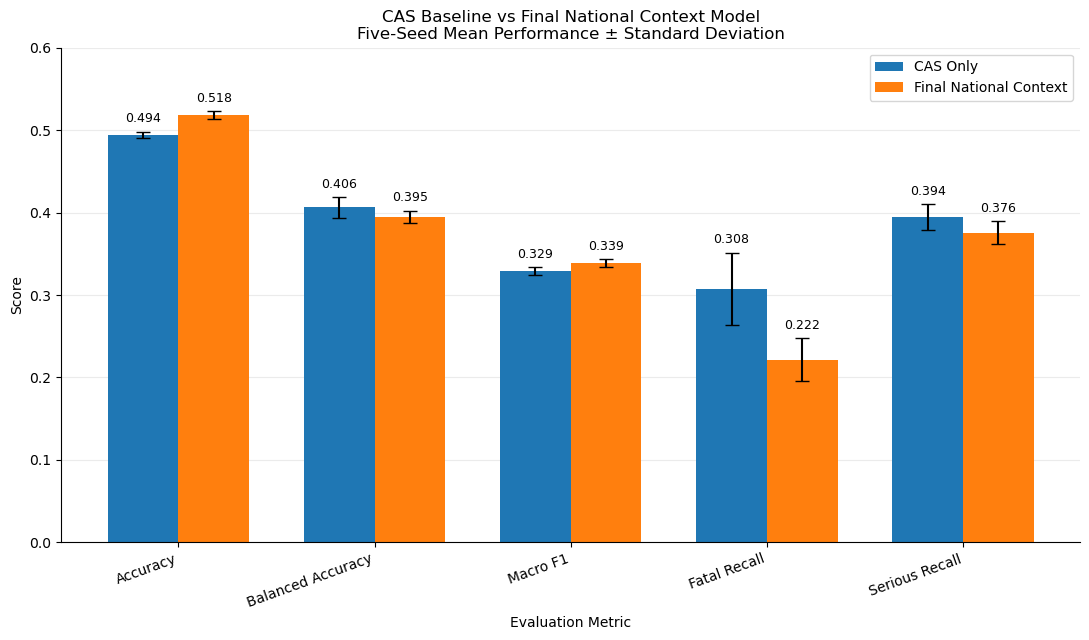


Saved:
C:\Users\ASUS\Desktop\Project_Roadcrash\results\figures\Figure_Final_Model_Performance_Comparison.png
C:\Users\ASUS\Desktop\Project_Roadcrash\results\figures\Figure_Final_Model_Performance_Comparison.pdf


In [17]:
# FIGURE 1: FINAL MODEL PERFORMANCE COMPARISON
# CAS Only vs Final National Context
# Five-seed mean ± standard deviation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# 1. Locate the project folder

PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (
            folder
            / "data"
            / "combined_context"
            / "final_five_seed_paired_results.csv"
        ).exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/combined_context/"
        "final_five_seed_paired_results.csv. "
        "Run Notebook 08 first and open this notebook "
        "inside the project folder."
    )

RESULTS_PATH = (
    PROJECT_ROOT
    / "data"
    / "combined_context"
    / "final_five_seed_paired_results.csv"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "results"
    / "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

paired = pd.read_csv(RESULTS_PATH)


# 2. Validate and align model results by seed
# Included here so this figure cell can run independently.

def paired_metric_values(frame, metric):
    required = {"Seed", "Model", metric}
    missing = required - set(frame.columns)

    if missing:
        raise ValueError(
            f"Notebook 08 results are missing columns: {sorted(missing)}"
        )

    model_names = [
        "CAS Only",
        "Final National Context"
    ]

    selected = frame.loc[
        frame["Model"].isin(model_names)
    ].copy()

    if selected.duplicated(["Seed", "Model"]).any():
        raise ValueError(
            "Duplicate seed/model rows in the saved results."
        )

    wide = selected.pivot(
        index="Seed",
        columns="Model",
        values=metric
    )

    if not set(model_names).issubset(wide.columns):
        raise ValueError(
            "Expected both CAS Only and Final National Context."
        )

    if set(wide.index) != {42, 7, 21, 84, 123}:
        raise ValueError(
            "Expected seeds 42, 7, 21, 84 and 123."
        )

    wide = wide[model_names].apply(
        pd.to_numeric,
        errors="raise"
    )

    if wide.isna().any().any():
        raise ValueError(
            "Missing metric values or incomplete paired seeds."
        )

    cas_values = wide["CAS Only"]
    final_values = wide["Final National Context"]

    return (
        cas_values,
        final_values,
        final_values - cas_values
    )


# 3. Calculate means and standard deviations

metrics = [
    ("Accuracy", "Accuracy"),
    ("Balanced Accuracy", "Balanced_Accuracy"),
    ("Macro F1", "Macro_F1"),
    ("Fatal Recall", "Fatal_Recall"),
    ("Serious Recall", "Serious_Recall")
]

metric_labels = [label for label, column in metrics]

cas_means = []
cas_sds = []

final_means = []
final_sds = []

for label, column in metrics:

    cas_values, final_values, gains = paired_metric_values(
        paired,
        column
    )

    cas_means.append(cas_values.mean())
    cas_sds.append(cas_values.std(ddof=1))

    final_means.append(final_values.mean())
    final_sds.append(final_values.std(ddof=1))


# 4. Plot

x = np.arange(len(metric_labels))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 6.5))

bars_cas = ax.bar(
    x - width / 2,
    cas_means,
    width,
    yerr=cas_sds,
    capsize=5,
    label="CAS Only"
)

bars_final = ax.bar(
    x + width / 2,
    final_means,
    width,
    yerr=final_sds,
    capsize=5,
    label="Final National Context"
)

ax.set_ylabel("Score")
ax.set_xlabel("Evaluation Metric")

ax.set_title(
    "CAS Baseline vs Final National Context Model\n"
    "Five-Seed Mean Performance ± Standard Deviation"
)

ax.set_xticks(x)

ax.set_xticklabels(
    metric_labels,
    rotation=20,
    ha="right"
)

ax.set_ylim(0, 0.60)
ax.legend()


# 5. Add labels above the error bars

def add_labels(bars, values, standard_deviations):
    for bar, value, sd in zip(
        bars,
        values,
        standard_deviations
    ):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + sd + 0.008,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

add_labels(bars_cas, cas_means, cas_sds)
add_labels(bars_final, final_means, final_sds)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.set_axisbelow(True)

fig.tight_layout()


# 6. Save

PNG_PATH = (
    FIGURE_DIR
    / "Figure_Final_Model_Performance_Comparison.png"
)

PDF_PATH = (
    FIGURE_DIR
    / "Figure_Final_Model_Performance_Comparison.pdf"
)

fig.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(PNG_PATH)
print(PDF_PATH)

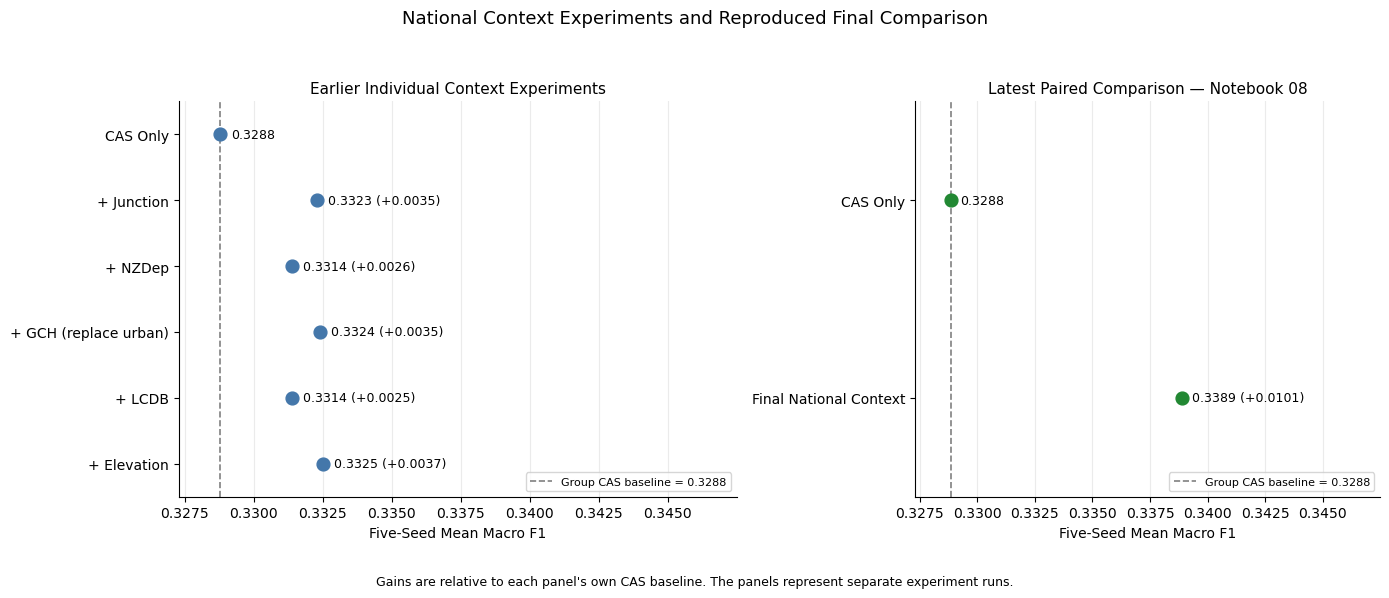


Saved:
C:\Users\ASUS\Desktop\Project_Roadcrash\results\figures\Figure_National_Context_MacroF1_Comparison.png
C:\Users\ASUS\Desktop\Project_Roadcrash\results\figures\Figure_National_Context_MacroF1_Comparison.pdf


In [18]:
# FIGURE 2: NATIONAL CONTEXT EXPERIMENT COMPARISON
# Separate panels for earlier individual experiments
# and the latest paired comparison from Notebook 08.

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# 1. Check that the updated Cell 24 has run

required_variables = [
    "national_context_summary",
    "latest_national_summary",
    "PROJECT_ROOT"
]

missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the updated national context summary cell first. "
        f"Missing variables: {missing_variables}"
    )


# 2. Use the project root detected in Cell 24

FIGURE_DIR = (
    Path(PROJECT_ROOT)
    / "results"
    / "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# 3. Prepare the two experiment groups

historical_df = national_context_summary.copy()
latest_df = latest_national_summary.copy()

label_map = {
    "CAS Only": "CAS Only",
    "CAS + Junction": "+ Junction",
    "CAS + NZDep": "+ NZDep",
    "CAS + GCH (replace urban)": "+ GCH (replace urban)",
    "CAS + LCDB": "+ LCDB",
    "CAS + Elevation": "+ Elevation",
    "Final National Context": "Final National Context"
}


# 4. Plot each group against its own baseline

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6),
    gridspec_kw={"width_ratios": [1.2, 1]},
    sharex=True
)

groups = [
    (
        axes[0],
        historical_df,
        "Earlier Individual Context Experiments",
        "#4477AA"
    ),
    (
        axes[1],
        latest_df,
        "Latest Paired Comparison — Notebook 08",
        "#228833"
    )
]

all_scores = np.concatenate([
    historical_df["Macro F1"].to_numpy(dtype=float),
    latest_df["Macro F1"].to_numpy(dtype=float)
])

score_range = max(
    float(np.ptp(all_scores)),
    0.005
)

label_offset = score_range * 0.04

for ax, frame, title, colour in groups:

    frame = frame.reset_index(drop=True)

    labels = (
        frame["Experiment"]
        .map(label_map)
        .fillna(frame["Experiment"])
        .tolist()
    )

    values = frame["Macro F1"].to_numpy(dtype=float)
    gains = frame["Macro F1 Gain"].to_numpy(dtype=float)

    baseline = frame.loc[
        frame["Experiment"].eq("CAS Only"),
        "Macro F1"
    ].iloc[0]

    y = np.arange(len(frame))

    ax.scatter(
        values,
        y,
        s=85,
        color=colour,
        zorder=3
    )

    ax.axvline(
        baseline,
        color="grey",
        linestyle="--",
        linewidth=1.2,
        label=f"Group CAS baseline = {baseline:.4f}"
    )

    for position, row in frame.iterrows():

        value = float(row["Macro F1"])
        gain = float(row["Macro F1 Gain"])

        if row["Experiment"] == "CAS Only":
            annotation = f"{value:.4f}"
        else:
            annotation = f"{value:.4f} ({gain:+.4f})"

        ax.text(
            value + label_offset,
            position,
            annotation,
            va="center",
            fontsize=9
        )

    ax.set_yticks(y)
    ax.set_yticklabels(labels)

    ax.set_ylim(
        len(frame) - 0.5,
        -0.5
    )

    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Five-Seed Mean Macro F1")

    ax.set_xlim(
        all_scores.min() - score_range * 0.15,
        all_scores.max() + score_range * 0.85
    )

    ax.grid(
        axis="x",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        loc="lower right",
        fontsize=8
    )

fig.suptitle(
    "National Context Experiments and Reproduced Final Comparison",
    fontsize=13
)

fig.text(
    0.5,
    0.02,
    "Gains are relative to each panel's own CAS baseline. "
    "The panels represent separate experiment runs.",
    ha="center",
    fontsize=9
)

fig.tight_layout(
    rect=[0, 0.07, 1, 0.94]
)


# 5. Save

PNG_PATH = (
    FIGURE_DIR
    / "Figure_National_Context_MacroF1_Comparison.png"
)

PDF_PATH = (
    FIGURE_DIR
    / "Figure_National_Context_MacroF1_Comparison.pdf"
)

fig.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(PNG_PATH)
print(PDF_PATH)

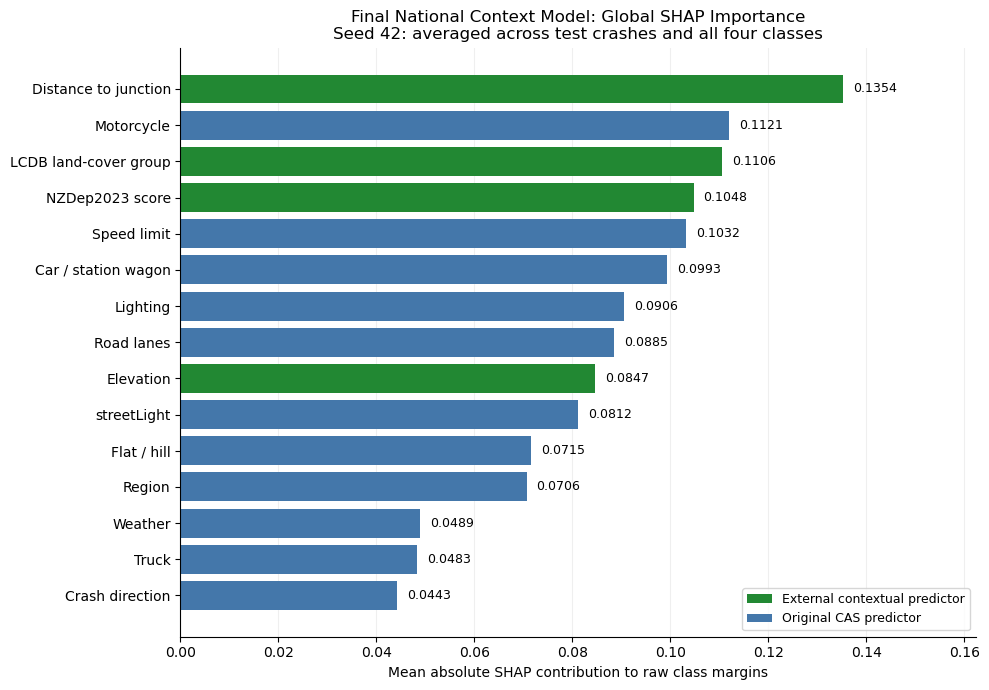


Saved:
C:\Users\ASUS\Desktop\Project_Roadcrash\results\figures\Figure_National_Global_SHAP_Importance.png
C:\Users\ASUS\Desktop\Project_Roadcrash\results\figures\Figure_National_Global_SHAP_Importance.pdf


In [19]:
# FIGURE 3: REGENERATED GLOBAL SHAP FEATURE IMPORTANCE
# Latest seed-42 national model

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# 1. Locate the regenerated SHAP file

RELATIVE_PATH = (
    Path("data")
    / "combined_context"
    / "shap_seed42"
    / "national_shap_global_seed42.csv"
)

PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / RELATIVE_PATH).exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find national_shap_global_seed42.csv. "
        "Run the SHAP cell in Notebook 08 first."
    )

global_shap_summary = pd.read_csv(
    PROJECT_ROOT / RELATIVE_PATH
)


# 2. Select the top 15 original predictors

plot_df = (
    global_shap_summary
    .sort_values("Mean_Absolute_SHAP", ascending=False)
    .head(15)
    .sort_values("Mean_Absolute_SHAP", ascending=True)
    .copy()
)

feature_labels = {
    "dist_to_junction_m": "Distance to junction",
    "motorcycle": "Motorcycle",
    "LCDB_Group_clean": "LCDB land-cover group",
    "NZDep2023_Score": "NZDep2023 score",
    "flatHill": "Flat / hill",
    "speedLimit": "Speed limit",
    "light": "Lighting",
    "roadLane": "Road lanes",
    "carStationWagon": "Car / station wagon",
    "Elevation_m": "Elevation",
    "region": "Region",
    "truck": "Truck",
    "weatherA": "Weather",
    "crashDirectionDescription": "Crash direction",
    "bicycle": "Bicycle"
}

context_features = {
    "dist_to_junction_m",
    "LCDB_Group_clean",
    "NZDep2023_Score",
    "Elevation_m"
}

labels = (
    plot_df["Feature"]
    .map(feature_labels)
    .fillna(plot_df["Feature"])
)

colours = [
    "#228833" if feature in context_features else "#4477AA"
    for feature in plot_df["Feature"]
]


# 3. Plot

fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    labels,
    plot_df["Mean_Absolute_SHAP"],
    color=colours
)

maximum = plot_df["Mean_Absolute_SHAP"].max()

for bar, value in zip(
    bars,
    plot_df["Mean_Absolute_SHAP"]
):
    ax.text(
        value + maximum * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center",
        fontsize=9
    )

ax.set_xlim(0, maximum * 1.20)

ax.set_xlabel(
    "Mean absolute SHAP contribution to raw class margins"
)

ax.set_title(
    "Final National Context Model: Global SHAP Importance\n"
    "Seed 42: averaged across test crashes and all four classes"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(axis="x", alpha=0.20)
ax.set_axisbelow(True)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(
            facecolor="#228833",
            label="External contextual predictor"
        ),
        Patch(
            facecolor="#4477AA",
            label="Original CAS predictor"
        )
    ],
    loc="lower right",
    fontsize=9
)

fig.tight_layout()


# 4. Save

FIGURE_DIR = PROJECT_ROOT / "results" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

PNG_PATH = (
    FIGURE_DIR
    / "Figure_National_Global_SHAP_Importance.png"
)

PDF_PATH = (
    FIGURE_DIR
    / "Figure_National_Global_SHAP_Importance.pdf"
)

fig.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(PNG_PATH)
print(PDF_PATH)

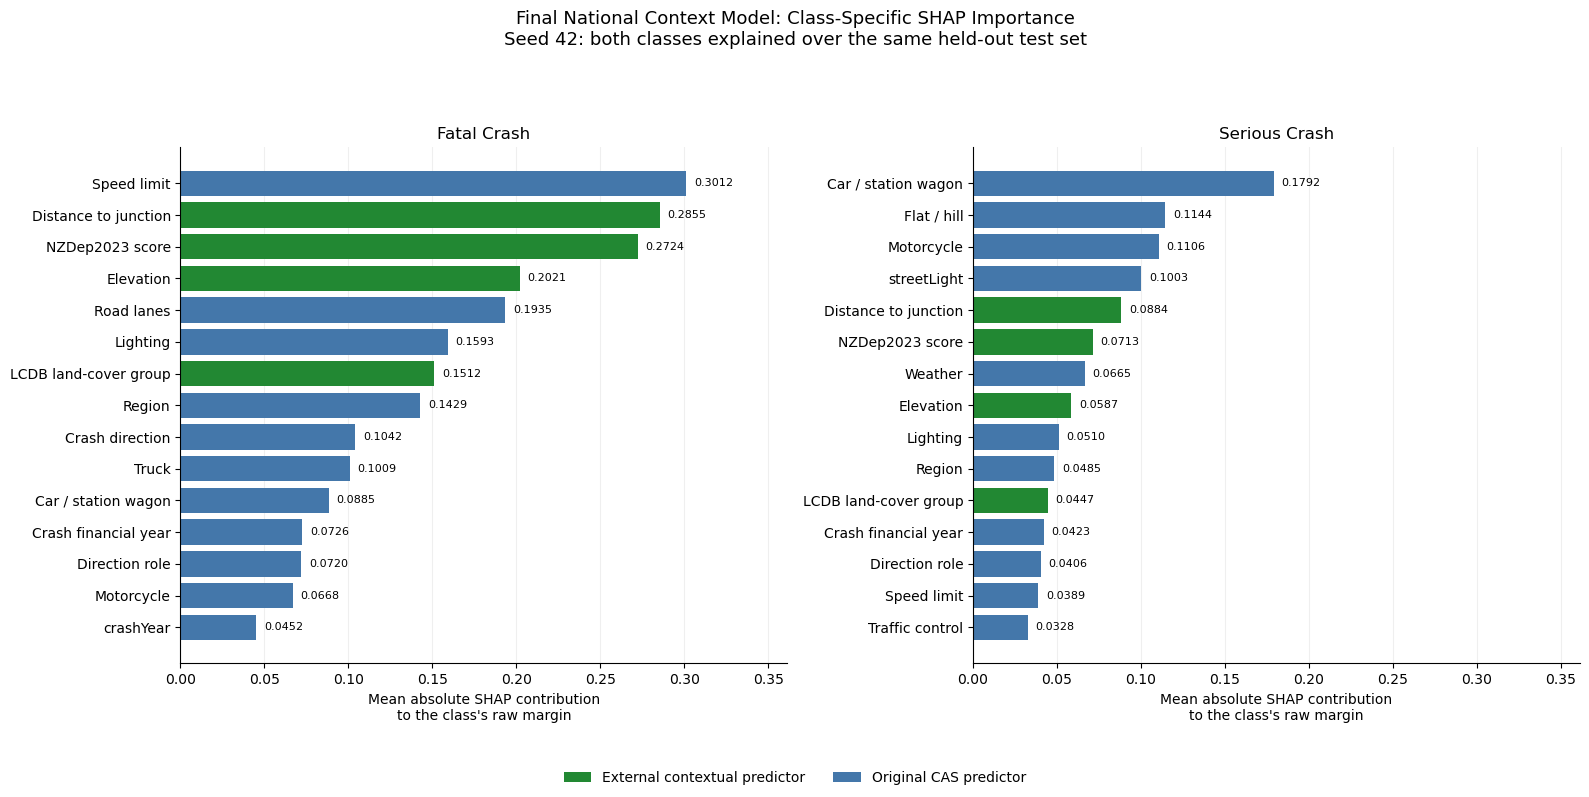


Saved:
C:\Users\ASUS\Desktop\Project_Roadcrash\results\figures\Figure_National_Fatal_Serious_SHAP_Importance.png
C:\Users\ASUS\Desktop\Project_Roadcrash\results\figures\Figure_National_Fatal_Serious_SHAP_Importance.pdf


In [20]:
# FIGURE 4: FATAL AND SERIOUS CLASS-SPECIFIC SHAP
# Latest seed-42 national model

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path


# 1. Locate regenerated class-specific results

RELATIVE_PATH = (
    Path("data")
    / "combined_context"
    / "shap_seed42"
    / "national_shap_by_class_seed42.csv"
)

PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / RELATIVE_PATH).exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find national_shap_by_class_seed42.csv. "
        "Run the SHAP cell in Notebook 08 first."
    )

class_shap_summary = pd.read_csv(
    PROJECT_ROOT / RELATIVE_PATH
)

required = {
    "Class",
    "Feature",
    "Mean_Absolute_SHAP"
}

missing = required - set(class_shap_summary.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

if class_shap_summary.duplicated(["Class", "Feature"]).any():
    raise ValueError("Duplicate class/feature rows.")


# 2. Labels and contextual predictors

feature_labels = {
    "dist_to_junction_m": "Distance to junction",
    "LCDB_Group_clean": "LCDB land-cover group",
    "NZDep2023_Score": "NZDep2023 score",
    "Elevation_m": "Elevation",
    "speedLimit": "Speed limit",
    "roadLane": "Road lanes",
    "light": "Lighting",
    "region": "Region",
    "truck": "Truck",
    "crashDirectionDescription": "Crash direction",
    "carStationWagon": "Car / station wagon",
    "directionRoleDescription": "Direction role",
    "motorcycle": "Motorcycle",
    "crashFinancialYear": "Crash financial year",
    "parkedVehicle": "Parked vehicle",
    "flatHill": "Flat / hill",
    "weatherA": "Weather",
    "trafficControl": "Traffic control",
    "bicycle": "Bicycle"
}

context_features = {
    "dist_to_junction_m",
    "LCDB_Group_clean",
    "NZDep2023_Score",
    "Elevation_m"
}

class_names = [
    "Fatal Crash",
    "Serious Crash"
]


# 3. Prepare top predictors for each class

plot_tables = {}

for class_name in class_names:

    subset = class_shap_summary.loc[
        class_shap_summary["Class"].eq(class_name)
    ]

    if subset.empty:
        raise ValueError(f"No SHAP results for {class_name}.")

    plot_tables[class_name] = (
        subset
        .sort_values("Mean_Absolute_SHAP", ascending=False)
        .head(15)
        .sort_values("Mean_Absolute_SHAP", ascending=True)
        .copy()
    )

shared_maximum = max(
    table["Mean_Absolute_SHAP"].max()
    for table in plot_tables.values()
)


# 4. Plot using the same horizontal scale

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 8),
    sharex=True
)

for ax, class_name in zip(axes, class_names):

    table = plot_tables[class_name]

    labels = (
        table["Feature"]
        .map(feature_labels)
        .fillna(table["Feature"])
    )

    colours = [
        "#228833" if feature in context_features else "#4477AA"
        for feature in table["Feature"]
    ]

    bars = ax.barh(
        labels,
        table["Mean_Absolute_SHAP"],
        color=colours
    )

    for bar, value in zip(
        bars,
        table["Mean_Absolute_SHAP"]
    ):
        ax.text(
            value + shared_maximum * 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.4f}",
            va="center",
            fontsize=8
        )

    ax.set_title(class_name)

    ax.set_xlabel(
        "Mean absolute SHAP contribution\n"
        "to the class's raw margin"
    )

    ax.set_xlim(
        0,
        shared_maximum * 1.20
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(axis="x", alpha=0.20)
    ax.set_axisbelow(True)

fig.suptitle(
    "Final National Context Model: Class-Specific SHAP Importance\n"
    "Seed 42: both classes explained over the same held-out test set",
    fontsize=13
)

fig.legend(
    handles=[
        Patch(
            facecolor="#228833",
            label="External contextual predictor"
        ),
        Patch(
            facecolor="#4477AA",
            label="Original CAS predictor"
        )
    ],
    loc="lower center",
    ncol=2,
    frameon=False
)

fig.tight_layout(
    rect=[0, 0.07, 1, 0.92]
)


# 5. Save

FIGURE_DIR = PROJECT_ROOT / "results" / "figures"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PNG_PATH = (
    FIGURE_DIR
    / "Figure_National_Fatal_Serious_SHAP_Importance.png"
)

PDF_PATH = (
    FIGURE_DIR
    / "Figure_National_Fatal_Serious_SHAP_Importance.pdf"
)

fig.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(PNG_PATH)
print(PDF_PATH)

Project root: C:\Users\ASUS\Desktop\Project_Roadcrash
Error file: C:\Users\ASUS\Desktop\Project_Roadcrash\data\combined_context\final_model_error_analysis_seed42.csv
Figure folder: C:\Users\ASUS\Desktop\Project_Roadcrash\results\figures
Severe Prediction Percentages


Predicted,Fatal Crash,Serious Crash,Minor Crash,Non-Injury Crash
Actual,,,,
Fatal Crash,21.54,46.15,16.92,15.38
Serious Crash,6.19,39.52,34.33,19.96


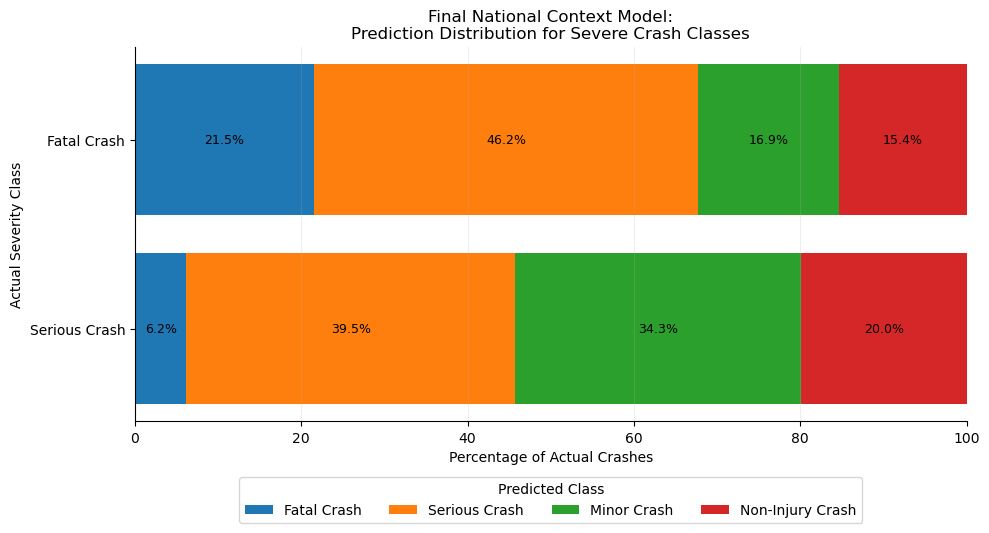


Saved:
C:\Users\ASUS\Desktop\Project_Roadcrash\results\figures\Figure_Severe_Class_Misclassification.png
C:\Users\ASUS\Desktop\Project_Roadcrash\results\figures\Figure_Severe_Class_Misclassification.pdf


In [21]:
# FIGURE 5: SEVERE-CLASS MISCLASSIFICATION PATTERN
# Final National Context Model, Seed 42
# Shows where actual Fatal and Serious crashes
# were classified across the four severity classes.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# 1. Paths

CURRENT_FOLDER = Path.cwd()

PROJECT_ROOT = None

for folder in [CURRENT_FOLDER, *CURRENT_FOLDER.parents]:

    candidate = (
        folder
        / "data"
        / "combined_context"
        / "final_model_error_analysis_seed42.csv"
    )

    if candidate.exists():
        PROJECT_ROOT = folder
        break


if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find final_model_error_analysis_seed42.csv "
        "inside data/combined_context from the current folder "
        "or any parent folder."
    )


ERROR_PATH = (
    PROJECT_ROOT
    / "data"
    / "combined_context"
    / "final_model_error_analysis_seed42.csv"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "results"
    / "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print(
    "Project root:",
    PROJECT_ROOT
)

print(
    "Error file:",
    ERROR_PATH
)

print(
    "Figure folder:",
    FIGURE_DIR
)


# 2. Load saved case-level error analysis

error_df = pd.read_csv(
    ERROR_PATH
)


# 3. Keep actual severe crashes only

severe_plot_df = (
    error_df[
        error_df["Actual"].isin(
            [
                "Fatal Crash",
                "Serious Crash"
            ]
        )
    ]
    .copy()
)


# 4. Prediction order

actual_order = [
    "Fatal Crash",
    "Serious Crash"
]

prediction_order = [
    "Fatal Crash",
    "Serious Crash",
    "Minor Crash",
    "Non-Injury Crash"
]


# 5. Row-normalised prediction percentages

severe_matrix = pd.crosstab(
    severe_plot_df["Actual"],
    severe_plot_df["Predicted"],
    normalize="index"
)

severe_matrix = (
    severe_matrix
    .reindex(
        index=actual_order,
        columns=prediction_order,
        fill_value=0
    )
    * 100
)


print(
    "Severe Prediction Percentages"
)

display(
    severe_matrix.round(2)
)


# 6. Create 100% stacked horizontal bar chart

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

left = np.zeros(
    len(actual_order)
)


for predicted_class in prediction_order:

    values = (
        severe_matrix[
            predicted_class
        ]
        .to_numpy()
    )

    bars = ax.barh(
        actual_order,
        values,
        left=left,
        label=predicted_class
    )

    for bar, value, start in zip(
        bars,
        values,
        left
    ):

        if value >= 5:

            ax.text(
                start + value / 2,
                bar.get_y()
                + bar.get_height() / 2,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=9
            )

    left += values


# 7. Appearance

ax.set_xlim(
    0,
    100
)

ax.set_xlabel(
    "Percentage of Actual Crashes"
)

ax.set_ylabel(
    "Actual Severity Class"
)

ax.set_title(
    "Final National Context Model:\n"
    "Prediction Distribution for Severe Crash Classes"
)

ax.invert_yaxis()

ax.grid(
    axis="x",
    alpha=0.20
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

ax.legend(
    title="Predicted Class",
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        -0.13
    ),
    ncol=4
)

plt.tight_layout()


# 8. Save

PNG_PATH = (
    FIGURE_DIR
    / "Figure_Severe_Class_Misclassification.png"
)

PDF_PATH = (
    FIGURE_DIR
    / "Figure_Severe_Class_Misclassification.pdf"
)


plt.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()


print(
    "\nSaved:"
)

print(
    PNG_PATH
)

print(
    PDF_PATH
)

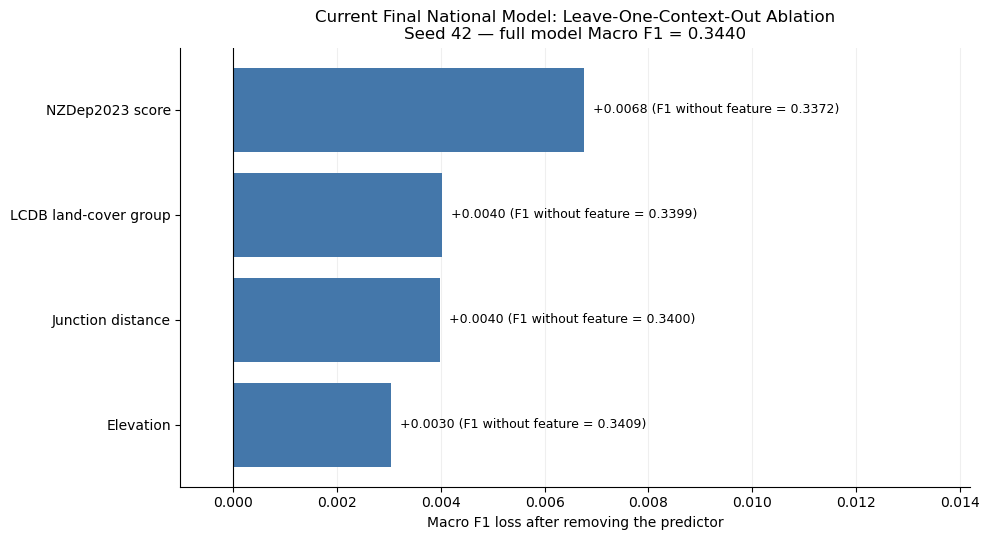


CURRENT FINAL MODEL ABLATION


,Seed,Model,Accuracy,Balanced_Accuracy,Macro_F1,Fatal_Recall,Serious_Recall,Removed_Feature,Number_of_Predictors,Macro_F1_Loss_When_Removed
0,42,Full Final National Context,0.520648,0.400707,0.343952,0.215385,0.395210,None,34,0.000000
1,42,Final Context without dist_to_junction_m,0.511328,0.402541,0.339964,0.230769,0.409182,dist_to_junction_m,33,0.003988
2,42,Final Context without NZDep2023_Score,0.512188,0.396146,0.337196,0.230769,0.377246,NZDep2023_Score,33,0.006756
3,42,Final Context without LCDB_Group_clean,0.513622,0.395095,0.339918,0.200000,0.395210,LCDB_Group_clean,33,0.004033
4,42,Final Context without Elevation_m,0.514482,0.404280,0.340911,0.246154,0.391218,Elevation_m,33,0.003041



Saved:
C:\Users\ASUS\Desktop\Project_Roadcrash\results\figures\Figure_Context_Ablation_MacroF1.png
C:\Users\ASUS\Desktop\Project_Roadcrash\results\figures\Figure_Context_Ablation_MacroF1.pdf


In [22]:
# FIGURE 6: CURRENT FINAL MODEL ABLATION
# Loads regenerated seed-42 results from Notebook 08.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# 1. Locate saved ablation results

RELATIVE_PATH = (
    Path("data")
    / "combined_context"
    / "final_context_ablation_seed42.csv"
)

PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / RELATIVE_PATH).exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find final_context_ablation_seed42.csv. "
        "Run the new ablation cell in Notebook 08 first."
    )

ablation_results = pd.read_csv(
    PROJECT_ROOT / RELATIVE_PATH,
    keep_default_na=False
)

required = {
    "Removed_Feature",
    "Macro_F1",
    "Macro_F1_Loss_When_Removed"
}

missing = required - set(ablation_results.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

if ablation_results["Removed_Feature"].duplicated().any():
    raise ValueError("Duplicate ablation configurations.")

full_rows = ablation_results.loc[
    ablation_results["Removed_Feature"].eq("None")
]

if len(full_rows) != 1:
    raise ValueError("Expected one complete-model reference row.")

FULL_MACRO_F1 = float(
    full_rows["Macro_F1"].iloc[0]
)

ablation_df = ablation_results.loc[
    ~ablation_results["Removed_Feature"].eq("None")
].copy()

expected_features = {
    "dist_to_junction_m",
    "NZDep2023_Score",
    "LCDB_Group_clean",
    "Elevation_m"
}

if set(ablation_df["Removed_Feature"]) != expected_features:
    raise ValueError("Expected four contextual feature removals.")

np.testing.assert_allclose(
    ablation_df["Macro_F1_Loss_When_Removed"],
    FULL_MACRO_F1 - ablation_df["Macro_F1"],
    rtol=1e-6,
    atol=1e-8
)


# 2. Prepare labels

feature_labels = {
    "dist_to_junction_m": "Junction distance",
    "NZDep2023_Score": "NZDep2023 score",
    "LCDB_Group_clean": "LCDB land-cover group",
    "Elevation_m": "Elevation"
}

ablation_df = (
    ablation_df
    .sort_values(
        "Macro_F1_Loss_When_Removed",
        ascending=False
    )
    .reset_index(drop=True)
)

labels = ablation_df["Removed_Feature"].map(
    feature_labels
)

losses = ablation_df[
    "Macro_F1_Loss_When_Removed"
].to_numpy()

colours = [
    "#4477AA" if loss >= 0 else "#CC6677"
    for loss in losses
]


# 3. Plot

fig, ax = plt.subplots(figsize=(10, 5.5))

y = np.arange(len(ablation_df))

ax.barh(
    y,
    losses,
    color=colours
)

ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.invert_yaxis()

ax.axvline(
    0,
    color="black",
    linewidth=0.8
)

scale = max(float(np.abs(losses).max()), 0.001)
offset = scale * 0.025

for position, row in ablation_df.iterrows():

    loss = row["Macro_F1_Loss_When_Removed"]
    reduced_f1 = row["Macro_F1"]

    ax.text(
        loss + offset if loss >= 0 else loss - offset,
        position,
        f"{loss:+.4f} (F1 without feature = {reduced_f1:.4f})",
        va="center",
        ha="left" if loss >= 0 else "right",
        fontsize=9
    )

ax.set_xlim(
    min(0.0, float(losses.min())) - scale * 0.15,
    max(0.0, float(losses.max())) + scale * 1.10
)

ax.set_xlabel(
    "Macro F1 loss after removing the predictor"
)

ax.set_title(
    "Current Final National Model: Leave-One-Context-Out Ablation\n"
    f"Seed 42 — full model Macro F1 = {FULL_MACRO_F1:.4f}"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    alpha=0.20
)

ax.set_axisbelow(True)

fig.tight_layout()


# 4. Save

FIGURE_DIR = PROJECT_ROOT / "results" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

PNG_PATH = (
    FIGURE_DIR
    / "Figure_Context_Ablation_MacroF1.png"
)

PDF_PATH = (
    FIGURE_DIR
    / "Figure_Context_Ablation_MacroF1.pdf"
)

fig.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("\nCURRENT FINAL MODEL ABLATION")
display(ablation_results)

print("\nSaved:")
print(PNG_PATH)
print(PDF_PATH)

### Ablation Interpretation

The leave-one-context-out experiment evaluated the final national model using the same seed-42 train/test split for every configuration. The full model contained 30 CAS predictors and four contextual predictors, giving 34 predictors in total. It achieved Macro F1 of 0.3440.

Removing any of the four contextual predictors reduced Macro F1:

- removing NZDep2023 score reduced Macro F1 by 0.0068, to 0.3372;
- removing LCDB land cover reduced it by 0.0040, to 0.3399;
- removing junction distance reduced it by 0.0040, to 0.3400; and
- removing elevation reduced it by 0.0030, to 0.3409.

Losses were calculated from unrounded scores, so they may differ slightly from subtraction of the displayed rounded values. The unrounded removal loss for land cover was slightly larger than the loss for junction distance.

Each contextual predictor contributed to Macro F1 within this model configuration and split. NZDep2023 produced the largest removal loss, although junction distance had the highest global SHAP importance. SHAP importance and retraining-based ablation measure different aspects of model behaviour.

The contribution was not uniform across evaluation metrics. Removing junction distance increased Fatal recall from 0.2154 to 0.2308 and Serious recall from 0.3952 to 0.4092. Removing elevation increased Fatal recall to 0.2462 but decreased Serious recall to 0.3912. Both removals increased Balanced Accuracy while reducing Macro F1.

The selected configuration therefore retained a trade-off between multiclass F1 performance and severe-class sensitivity.

This experiment used one random split. It does not establish multi-seed consistency of each individual removal or causal importance. GCH was not included, so these results do not evaluate the decision to exclude GCH.